# Визуализация данных. Анализ данных

© Петров М.В., старший преподаватель кафедры киберфотоники, Самарский университет

# Лекция 9. Градиентный бустинг

## Содержание

1. [Введение](#91-введение)
2. [AdaBoost](#92-adaboost)
3. [Градиентный бустинг](#93-градиентный-бустинг)
4. [XGBoost](#94-xgboost)
5. [CatBoost](#95-catboost)
6. [Датасет `Rain in Australia`](#96-датасет-rain-in-australia)
7. [Подготовка данных](#98-классификация)
8. [Классификация](#98-классификация)
9. [Важность признаков. Библиотека SHAP](#99-важность-признаков-библиотека-shap)

## 9.1 Введение

Источники:
- [Открытый курс машинного обучения. Тема 10. Градиентный бустинг @ Хабр](https://habr.com/ru/companies/ods/articles/327250/)
- [Алгоритм AdaBoost](https://habr.com/ru/companies/otus/articles/503888/)
- [Бустинг, AdaBoost @ ИТМО](https://neerc.ifmo.ru/wiki/index.php?title=%D0%91%D1%83%D1%81%D1%82%D0%B8%D0%BD%D0%B3,_AdaBoost)
- [XGBoost @ ИТМО](https://neerc.ifmo.ru/wiki/index.php?title=XGBoost)
- [Градиентный бустинг. Реализация с нуля на Python и разбор особенностей его модификаций (XGBoost, CatBoost, LightGBM) @ Хабр](https://habr.com/ru/articles/799725/)
- [LightGBM @ GitHub](https://github.com/Microsoft/LightGBM)
- [Разбираем особенности алгоритмов CatBoost и LightGBM: какой от них профит @ Хабр](https://habr.com/ru/companies/tochka/articles/751012/)
- [Туториал по использованию библиотеки CatBoost @ GitHub](https://github.com/catboost/tutorials/blob/master/ru/ml_session_2018_tutorial_ru.ipynb)
- [Mastering Gradient Boosting with CatBoost @ GitHub](https://github.com/catboost/tutorials/blob/master/events/2019_pydata_london/pydata_london_2019.ipynb)
- [CatBoost @ Хабр](https://habr.com/ru/companies/otus/articles/778714/)
- [Быстрый градиентный бустинг с CatBoost @ Хабр](https://habr.com/ru/companies/otus/articles/527554/)
- [sklearn.ensemble.AdaBoostClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html)
- [sklearn.ensemble.GradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html)
- [CatBoost tutorials](https://catboost.ai/en/docs/concepts/tutorials)
- [Градиентный бустинг с CATBOOST (часть 3/3) @ Хабр](https://habr.com/ru/articles/648939/)
- [Что внутри черного ящика: понимаем работу ML-модели с помощью SHAP @ Хабр](https://habr.com/ru/companies/wunderfund/articles/739744/)


***Бустинг*** &ndash; ансамблевый метод машинного обучения, целью которого является объединение нескольких *слабых* моделей предсказания для создания одной *сильной*. Слабая модель &ndash; это такая, которая выполняет предсказания немного лучше, чем наугад, в то время как сильная модель обладает высокой предсказательной способностью. Цель бустинга &ndash; улучшить точность предсказаний.

Бустинг работает путём последовательного добавления моделей в ансамбль. Каждая следующая модель строится таким образом, чтобы исправлять ошибки, сделанные предыдущими моделями. Это достигается путём фокусировки на наиболее проблемных данных, которые были неверно классифицированы или предсказаны ранее. Одной из основных фич бустинга является динамическое взвешивание обучающих данных. После каждого этапа обучения модели в ансамбле данные, на которых были допущены ошибки, получают *больший* вес. Это означает, что последующие модели уделяют больше внимания именно этим трудным случаям. Несмотря на свою мощь, бустинг может быть склонен к переобучению, особенно если в ансамбле слишком много моделей или они слишком сложные. Для контроля переобучения используется ранняя остановка (*early stopping*).

Исходные алгоритмы, предложенные Робертом Шапире (рекурсивное доминирование, англ. *recursive majority gate formulation*) и Йоавом Фройндом (бустинг по доминированию), не были адаптивными и не могли дать полного преимущества слабых обучений. Шапире и Фройнд затем разработали ***AdaBoost*** (*Adaptive Boosting*) &ndash; адаптивный алгоритм бустинга, который выиграл престижную премию Гёделя.

## 9.2 AdaBoost

Слабый обучающий алгоритм или классификатор &ndash; это обучающий алгоритм, который работает лучше, чем случайное угадывание, и работать хорошо он будет в случае переобучения, поскольку при большом наборе слабых классификаторов, любой слабый классификатор будет работать лучше, чем случайная выборка. В качестве слабого классификатора часто используется обычный порог (*threshold*) по определённому признаку. Если признак лежит выше порогового значения, чем было спрогнозировано, он относится к положительной области, в противном случае &ndash; к отрицательной.

$AdaBoost$ означает «Adaptive Boosting» или адаптивный бустинг. Он превращает слабые обучающие алгоритмы в сильные для решения проблем классификации. Уравнение *сильного* классификатора выглядит как линейная комбинация *слабых* классификаторов:

$$
\newcommand{\argminu}[1]{\underset{#1}{\mathrm{argmin}}\,}
$$

$$
f(x) = \displaystyle\sum_{t = 1}^{T}\alpha_t h_t(x),
$$

где $h_t(x): X \rightarrow \{-1, +1\}$ &ndash; $t$-ый слабый классификатор, $\alpha_t$ &ndash; его вес.

$H(x) = sign\left(f(x)\right)$ &ndash; *сильный* окончательный классификатор.

### Алгоритм

Пусть у нас есть $m$ точек: $(x_1, y_1), \dots, (x_m, y_m), x_i \in X, y_i \in \{-1, +1\}$.  
Инициализация весов $1$-го классификатора: $D_1(i) = \displaystyle\frac{1}{m}$.  
Для $t = 1, \dots, T$:
- $h_t(x) = \argminu{h_t \in H}\epsilon_t, \epsilon_t = \displaystyle\sum_{i = 1}^{m}D_t(i)\left[y_i \neq h_t(x_i)\right]$
- $\alpha_t = \displaystyle\frac{1}{2} \log{\displaystyle\frac{1 - \epsilon_t}{\epsilon_t}}$
- $D_{t + 1}(i) = \displaystyle\frac{D_t(i) \exp\left(-\alpha_t y_i h_t(x_i)\right)}{Z_t}$, $Z_t$ &ndash; нормализующий параметр:  
  $Z_t = \displaystyle\sum_{i = 1}^{m} D_{t + 1}(i) = \displaystyle\sum_{i = 1}^{m} D_t(i) \exp\left(-\alpha_t y_i h_t(x_i)\right) = 1$
   > $\exp\left(-\alpha_t y_i h_t(x_i)\right) = \begin{cases}< 1, & y_i = h_t(x_i) \\ > 1, & y_i \neq h_t(x_i)\end{cases}$
- $F_t(x) = F_{t - 1}(x) + \alpha_t h_t(x)$  

Таким образом, после выбора оптимального классификатора $h_{t}$ для распределения $D_{t}$, объекты $x_{i}$, которые классификатор $h_{t}$ идентифицирует корректно, имеют веса меньшие, чем те, которые идентифицируются некорректно. Следовательно, когда алгоритм тестирует классификаторы на распределении $D_{t+1}$, он будет выбирать классификатор, который лучше идентифицирует объекты, неверно распознаваемые предыдущим классификатором.

$AdaBoost$ можно использовать для распознавания лиц, поскольку он является стандартным алгоритмом для таких задач. Он использует каскад отбраковки, состоящий из нескольких слоев классификаторов. Когда область распознавания не обнаруживает лица ни на одном слое, она отбраковывается. Первый классификатор в области отбрасывает отрицательную область, чтобы свести стоимость вычислений к минимуму. Несмотря на то, что $AdaBoost$ используется для объединения слабых классификаторов, принципы $AdaBoost$ также используются для поиска лучших признаков для каждого слоя в каскаде.

### Достоинства и недостатки

#### Достоинства

- Простота реализации
- Хорошая обобщающая способность. В реальных задачах удаётся строить композиции, превосходящие по качеству базовые алгоритмы. Обобщающая способность может улучшаться по мере увеличения числа базовых алгоритмов
- Время построения композиции практически полностью определяется временем обучения базовых алгоритмов
- Возможность идентифицировать выбросы. Это наиболее «трудные» объекты $x_i$, для которых в процессе наращивания композиции веса принимают наибольшие значения

#### Недостатки

- Склонен к переобучению при наличии значительного уровня шума в данных
- Требует достаточно длинных обучающих выборок. Другие методы линейной коррекции, в частности, *бэггинг*, способны строить алгоритмы сопоставимого качества по меньшим выборкам данных  
  
  > Бэггинг &ndash; ансамблевый метод машинного обучения, который повышает стабильность и точность алгоритмов (часто деревьев решений), уменьшает дисперсию и предотвращает переобучение. Базовые модели обучаются параллельно на разных случайных подвыборках данных (*bootstrap*) и объединяются путем голосования или усреднения.
  > Примером бэггинга служит модель случайного леса (Random Forest).

## 9.3 Градиентный бустинг

В 1999 году от Jerome Friedman появилось обобщение наработок алгоритмов бустинга &ndash; градиентный бустинг, он же *Gradient Boosting (Machine)*, он же *GBM*. Этой работой Friedman сразу задал статистическую базу для создания многих алгоритмов, предоставив общий подход бустинга как оптимизации в функциональном пространстве.

Пусть у нас есть $m$ пар признаков $x$ и целевых переменных $y$: $\left\{(x_i, y_i)\right\}, i = \overline{1, n}$, на котором мы будем восстанавливать зависимость вида $y = f(x)$. Восстанавливать будем приближением $\hat f(x)$, а для понимания, какое приближение лучше, у нас также будет функция потерь $L(y, f)$, которую мы будем минимизировать:

$$
\renewcommand{\argminu}[1]{\underset{#1}{\mathrm{argmin}}\,}
$$

$$
\begin{align*}
&y \approx \hat f(x) \\
&\hat f(x) = \argminu{f(x)} L\left(y, f(x)\right)
\end{align*}
$$

Функция $L(y, f)$ должна быть дифференцируемой. Будем искать наши приближения $\hat f(x)$ так, чтобы в среднем минимизировать функцию потерь на тех данных, что есть:

$$
\hat f(x) = \argminu{f(x)}\mathbb{E}_{x,y}\left[L(y, f(x))\right]
$$

Функциональное пространство функций $f(x)$ бесконечномерно. Поэтому чтобы хоть как-то решить задачу, в машинном обучении обычно ограничивают пространство поиска каким-нибудь конкретным параметризованным семейством функций $f(x, \theta), \theta \in \mathbb{R}^d$. Это сильно упрощает задачу, так как она сводится к уже вполне решаемой оптимизации значений параметров:

$$
\begin{align*}
&\hat f(x) = f(x, \hat\theta), \\
&\hat\theta = \argminu{\theta}\mathbb{E}_{x,y}\left[L(y, f(x, \theta))\right]
\end{align*}
$$

Аналитические решения для получения оптимальных параметров $\hat \theta$ в одну строку существуют достаточно редко, поэтому параметры обычно приближают итеративно. Сначала нам надо выписать эмпирическую функцию потерь $L_{\theta}(\hat \theta)$, показывающую, насколько хорошо мы их оценили по имеющимся у нас данным. Также выпишем наше приближение $\hat \theta$ за $M$ итераций в виде суммы:

$$
\begin{align*}
&\hat \theta = \displaystyle\sum_{i = 1}^M \hat \theta_i, \\ 
&L_{\theta}(\hat \theta) = \displaystyle\sum_{i = 1}^N L\left(y_i, f(x_i, \hat \theta)\right)
\end{align*}
$$

Дело за малым &ndash; осталось только взять подходящий итеративный алгоритм, которым мы будем минимизировать $L_{\theta}(\hat \theta)$. Самый простой и часто используемый вариант &ndash; градиентный спуск.

***Градиентный спуск*** &ndash; это итеративный алгоритм оптимизации, используемый для минимизации функции, чаще всего функции потерь в контексте машинного обучения. Он работает путем нахождения направления, в котором функция потерь уменьшается наиболее быстро, и делает шаги в этом направлении для постепенного уменьшения значения функции потерь.

Виды градиентного спуска:
- *Пакетный градиентный спуск* (*Batch Gradient Descent*).  
   Вычисляет градиент функции потерь по всему обучающему набору данных. Это точно, но может быть очень медленным на больших наборах данных.
- *Стохастический градиентный спуск* (*Stochastic Gradient Descent*, $SGD$).  
   Вычисляет градиент для каждого обучающего примера по отдельности и обновляет параметры. Это быстро, но изменения параметров могут быть очень «шумными».
- *Мини-пакетный градиентный спуск* (*Mini-batch Gradient Descent*).  
   Компромисс между двумя предыдущими методами, вычисляет градиенты на небольших группах обучающих примеров.

Для него нужно выписать градиент $\nabla L_{\theta}(\hat \theta)$ и добавлять наши итеративные оценки $\hat \theta_i$ вдоль него (со знаком минус &ndash; мы же хотим уменьшить ошибку, а не нарастить). И все, надо только как-то инициализировать наше первое приближение $\hat \theta_0$ и выбрать, сколько итераций $M$ мы эту процедуру будем продолжать. В нашем неэффективном по памяти виде хранения приближений $\hat \theta$ наивный алгоритм будет выглядеть следующим образом:

1. Инициализировать начальное приближение параметров $\hat \theta = \hat \theta_0$
2. Для каждой итерации $t = 1, \dots, M$ повторять:
   - Вычислить градиент функции потерь $\nabla L_{\theta}(\hat \theta)$ при текущем приближении $\hat \theta$:  
     $\nabla L_{\theta}(\hat \theta) = \left[\displaystyle\frac{\partial L\left(y, f(x, \theta)\right)}{\partial \theta}\right]_{\theta = \hat{\theta}}$
   - Задать текущее итеративное приближение $\hat \theta_t$ на основе вычисленного градиента  
     $\hat \theta_t \leftarrow −\nabla L_{\theta}(\hat \theta)$
   - Обновить приближение параметров $\hat \theta$:
     $\hat \theta \leftarrow \hat \theta + \hat \theta_t = \displaystyle\sum_{i = 0}^t \hat \theta_i$
3. Сохранить итоговое приближение $\hat \theta$  
   $\hat \theta = \displaystyle\sum_{i = 0}^M \hat \theta_i$
4. Пользоваться найденной функцией $\hat f(x) = f(x, \hat \theta)$ по назначению.

<div align="center">
  <img src="images/gd_1.gif" height="292" title="Градиентный спуск"/>
  <img src="images/gd_2.gif" height="292" title="Градиентный спуск"/>
  
  Рисунок 1 &ndash; Градиентный спуск
</div>

### Функциональный градиентный спуск

Представим, что мы можем проводить оптимизацию в функциональном пространстве и итеративно искать приближения $\hat f(x)$ в виде самих функций. Выпишем наше приближение в виде суммы инкрементальных улучшений, каждое из которых является функцией. Для удобства сразу будем считать эту сумму, начиная с начального приближения $\hat f_0(x)$:

$$
\hat f(x) = \displaystyle\sum_{i = 0}^M \hat f_i(x)
$$

Магии пока не случилось, мы просто решили, что будем искать наше приближение $\hat f(x)$ не в виде одной большой модели с кучей параметров (как, например, нейросеть), а в виде суммы функций, делая вид, что таким образом мы двигаемся в функциональном пространстве. Чтобы решить задачу, нам все равно придется ограничить свой поиск каким-то семейством функций $\hat f(x) = h(x, \theta)$. Но, во-первых, сумма моделей может быть сложнее, чем любая модель из этого семейства (сумму двух деревьев-пней глубины $1$ уже не приблизить одним пнем). Во-вторых, общая задача все еще происходит в функциональном пространстве. Сразу учтем, на каждом шаге для функций нам понадобится подбирать оптимальный коэффициент $\rho \in \mathbb{R}$. Для шага $t$ задача выглядит следующим образом:

$$
\begin{alignat*}{2}
&\hat f(x) &&= \displaystyle\sum_{i = 0}^{t - 1} \hat f_i(x), \\
&(\rho_t, \theta_t) &&= \argminu{\rho,\theta}\mathbb{E}_{x,y}\left[L\left(y, \hat f(x) + \rho \cdot h(x, \theta)\right)\right], \\
&\hat f_t(x) &&= \rho_t \cdot h(x, \theta_t)
\end{alignat*}
$$

А вот теперь время магии. Мы выписывали все наши задачи в общем виде, словно мы можем просто так брать и обучать какие угодно модели $h(x, \theta)$ относительно каких угодно функций потерь $L\left(y, f(x, \theta)\right)$. На практике это крайне сложно, поэтому был придуман простой способ свести задачу к чему-то решаемому. Зная выражение градиента функции потерь, мы можем посчитать его значения на наших данных. Так давайте обучать модели так, чтобы наши предсказания были наиболее скоррелированными с этим градиентом (со знаком минус). То есть будем решать задачу МНК-регрессии, пытаясь выправлять предсказания по этим остаткам. И для классификации, и для регрессии, и для ранжирования под капотом мы все время будем минимизировать квадрат разности между псевдо-остатками $r$ и нашими предсказаниями. Для шага $t$ итоговая задача выглядит следующим образом:

$$
\begin{alignat*}{2}
&\hat f(x) &&= \displaystyle\sum_{i = 0}^{t - 1} \hat f_i(x), \\
&r_{it} &&= -\left[\displaystyle\frac{\partial L\left(y_i, f(x_i)\right)}{\partial f(x_i)}\right]_{f(x) = \hat f(x)}, \quad i = \overline{1,n}, \\
&\theta_t &&= \displaystyle\argminu{\theta} \displaystyle\sum_{i = 1}^{n} \left(r_{it} - h(x_i, \theta)\right)^2, \\
&\rho_t &&= \argminu{\rho} \displaystyle\sum_{i = 1}^{n} L\left(y_i, \hat f(x_i) + \rho \cdot h(x_i, \theta_t)\right)
\end{alignat*}
$$

### Классический $GBM$ алгоритм Friedman'а

Теперь у нас есть все необходимое, чтобы наконец выписать GBM алгоритм, предложенный Jerome Friedman в 1999 году. Мы все так же решаем общую задачу обучения с учителем. На вход алгоритма нужно собрать несколько составляющих:
- набор данных $\left\{(x_i, y_i)\right\}, i = \overline{1,n}$;
- число итераций $M$;
- выбор функции потерь $L(y, f)$ с выписанным градиентом;
- выбор семейства функций базовых алгоритмов $h(x, \theta)$, с процедурой их обучения;
- дополнительные гиперпараметры $h(x, \theta)$, например, глубина дерева у деревьев решений.

Единственный момент, который остался без внимания &ndash; начальное приближение $f_0(x)$. Для простоты, в качестве инициализации используют просто константное значение $\gamma$. Его, а также оптимальный коэффициент $\rho$ находят бинарным поиском, или другим `line search` алгоритмом относительно исходной функции потерь (а не градиента). Итак, $GBM$ алгоритм:

1. Инициализировать $GBM$ константным значением $\hat f(x) = \hat f_0, \hat f_0 = \gamma, \gamma \in \mathbb{R}$  
   $\hat f_0 = \argminu{\gamma} \displaystyle\sum_{i = 1}^{n} L(y_i, \gamma)$
2. Для каждой итерации $t = 1, \dots, M$ повторять:
   - Вычислить псевдо-остатки $r_t$:  
     $r_{it} = -\left[\displaystyle\frac{\partial L\left(y_i, f(x_i)\right)}{\partial f(x_i)}\right]_{f(x)=\hat f(x)}, \quad i = \overline{1,n}$
   - Построить новый базовый алгоритм $h_t(x)$ как регрессию на псевдо-остатках $\left\{(x_i, r_{it})\right\}, i = \overline{1,n}$
   - Найти оптимальный коэффициент $\rho_t$ при $h_t(x)$ относительно исходной функции потерь:  
     $\rho_t = \argminu{\rho} \displaystyle\sum_{i = 1}^{n} L\left(y_i, \hat f(x_i) + \rho \cdot h(x_i, \theta)\right)$
   - Сохранить $\hat f_t(x) = \rho_t \cdot h_t(x)$
   - Обновить текущее приближение $\hat f(x)$:  
     $\hat f(x) = \hat f(x) + \hat f_t(x) = \displaystyle\sum_{i = 0}^{t} \hat f_i(x)$
3. Скомпоновать итоговую $GBM$ модель $\hat f(x)$:  
   $\hat f(x) = \displaystyle\sum_{i = 0}^M \hat f_i(x)$

### $LightGBM$

$LightGBM$ &ndash; это реализация градиентного бустинга с открытым исходным кодом, библиотека программного обеспечения и алгоритм машинного обучения. То есть проект очень похож на *Extreme Gradient Boosting* &ndash; $XGBoost$.

LightGBM была описана в статье 2017 года [LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://papers.nips.cc/paper/6907-lightgbm-a-highly-efficient-gradient-boosting-decision-tree). Реализация вводит две ключевые идеи: *GOSS* и *EFB*.

***Градиентная односторонняя выборка*** (***Gradient-based One-Side Sampling***, ***GOSS***) является модификацией градиентного бустинга, который фокусирует внимание на тех учебных примерах, которые приводят к большему градиенту, в свою очередь, ускоряя обучение и уменьшая вычислительную сложность метода. У нас есть некоторые наблюдения, в которых градиент большой. Обычно таргет на них хуже предсказывается (т.е. больший потенциал для улучшения качества модели), чем на наблюдениях, где градиент маленький.  Хотелось бы, обучаясь, обратить большее внимание на эти наблюдения, чем на наблюдения с маленьким градиентом.

***Объединение взаимоисключающих признаков*** (***Exclusive Feature Bundling***, ***EFB***) &ndash; связка взаимоисключающих признаков. Идея такая: вместо $k$-признаков, построить $p$-связок $p \leq k$ и использовать только их при нахождении оптимальной точки расщепления при построении деревьев. Причём построение этих связок осуществляется только один раз &ndash; в самом начале. Сложность этого действия $O(k^2)$.

## 9.4 XGBoost

***XGBoost*** (*eXtreme Gradient Boosting*) &ndash; это библиотека с открытым исходным кодом, используемая в машинном обучении и предоставляющая функциональность для решения задач, связанных с регуляризацией градиентного бустинга.

Основные особенности $XGBoost$, отличающие его от других алгоритмов градиентного бустинга, включают:
- умная штрафовка деревьев;
- пропорциональное уменьшение узлов листьев;
- метод Ньютона в оптимизации;
- дополнительный параметр рандомизации;
- реализация на одиночных, распределенных системах и out-of-core вычислениях;
- автоматический отбор признаков.

В отличие от $GBM$ в $XGboost$ изначальный прогноз регрессионного дерева устанавливается $f_0 (x) = 0.5$ и вместо пней с глубиной $3$ берутся более глубокие деревья с листьями в диапазоне от $8$ до $32$ как в случае регрессии, так и классификации, а к функции потерь добавляется регуляризация ($L_1$ или $L_2$ на выбор), которая штрафует дерево с высокой суммой нормы значений в листьях. Данная сумма представлена в виде целевой функции, расчёт значений которой аппроксимируется разложением в ряд Тейлора 2-го порядка.

### Алгоритм

Пусть дано:
- набор данных $\left\{(x_i, y_i)\right\}, i = \overline{1,n}$;
- число итераций $M$;
- функция потерь $L(y, f)$ с выписанным градиентом;
- скорость обучения $\alpha$.

Сам алгоритм:

1. Инициализировать модель константным значением:
   $\hat f_0(x) = \argminu{\theta} \displaystyle\sum_{i = 1}^{n} L(y_i, \theta)$
2. Для каждой итерации $t = 1, \dots, M$ повторять:
   - Вычислить «градиенты» и «гессианы»:  
     $\begin{aligned}g_t(x_i) &= \left[\displaystyle\frac{\partial L\left(y_i, f(x_i)\right)}{\partial f(x_i)}\right]_{f(x) = \hat f_{t - 1}(x)}, \quad i = \overline{1,n} \\
     h_t(x_i) &= \left[\displaystyle\frac{\partial^2 L\left(y_i, f(x_i)\right)}{\partial f^2(x_i)}\right]_{f(x)=\hat f_{t - 1}(x)}, \quad i = \overline{1,n}\end{aligned}$
   - Построить новый базовый алгоритм с использованием обучающего множества $\left\{(x_i, -\displaystyle\frac{\hat g_t(x_i)}{\hat h_t(x_i)})\right\}, i = \overline{1,n}$:  
     $\hat \varphi_t(x) = \argminu{\varphi \in \Phi} \displaystyle\sum_{i = 1}^{n} \displaystyle\frac{1}{2} \hat h_t(x_i) \left[-\displaystyle\frac{\hat g_t(x_i)}{\hat h_t(x_i)} - \varphi(x_i)\right]^2 \\
     \hat f_t(x) = \alpha \varphi_t(x)$
   - Обновить текущее приближение $\hat f(x)$:  
     $\hat f(x) = \hat f(x) + \hat f_{t - 1}(x)$
3. Скомпоновать итоговую модель $\hat f(x)$:  
   $\hat f(x) = \hat f_M(x) = \displaystyle\sum_{i = 0}^M \hat f_i(x)$

Функция для оптимизации градиентного бустинга:  
$$
L^t = \displaystyle\sum_{i = 1}^n L\left(y_i, \hat f_t(x_i)\right) + \Omega(f_t) = \displaystyle\sum_{i = 1}^n L\left(y_i, \hat f_{t - 1}(x_i) + f_t(x_i)\right) + \omega(f_t).
$$

$\omega(f)$ &ndash; регуляризация функции $f$:
$$
\omega(f) = \gamma T + \displaystyle\frac{1}{2} \lambda ||\omega||^2 = \gamma T + \displaystyle\frac{1}{2} \lambda \displaystyle\sum_{j = 1}^T \omega_j^2,
$$
где $T$ &ndash; количество вершин в дереве, $\omega$ &ndash; значения в листьях (*the vector of scores on leaves*), $\gamma$ и $\lambda$ &ndash; параметры регуляризации.

$\omega(f)$ отвечает за "сложность" построенного дерева:

$$
f_t(x) = \omega_{q(x)}, \omega \in R^T, q: R^d \rightarrow {1, 2, \ldots, T},
$$
где $\omega$ &ndash; значения в листьях, $q$ &ndash; функция, которая соотносит точку данных из набора данных в соответствующий лист дерева, $T$ &ndash; количество листьев.

Дальше с помощью разложения Тейлора до второго члена можем приблизить оптимизируемую функцию $L^t$ следующим выражением:
$$
\begin{alignat*}{2}
&L^t &&= \displaystyle\sum_{i = 1}^n L\left(y_i, \hat f_{t - 1}(x_i) + g_t(x_i) f_t(x_i) + \displaystyle\frac{1}{2} h_t(x_i) f_t^2(x_i)\right) + \Omega(f_t) =\\
&&&= \displaystyle\sum_{i = 1}^n L\left(y_i, \hat f_{t - 1}(x_i) + g_t(x_i) f_t(x_i) + \displaystyle\frac{1}{2} h_t(x_i) f_t^2(x_i)\right) + \gamma T + \displaystyle\frac{1}{2} \lambda \displaystyle\sum_{j = 1}^{T} \omega_j^2\\
&g_t(x_i) &&= \left[\displaystyle\frac{\partial L\left(y_i, f(x_i)\right)}{\partial f(x_i)}\right]_{f(x) = \hat f_{t - 1}(x)} \\
&h_t(x_i) &&= \left[\displaystyle\frac{\partial^2 L\left(y_i, f(x_i)\right)}{\partial f^2(x_i)}\right]_{f(x)=\hat f_{t - 1}(x)}
\end{alignat*}
$$

$L^t$ можно переписать в следующем виде:

$$
\begin{alignat*}{2}
&L^t &&= \displaystyle\sum_{i = 1}^n L\left(y_i, \hat f_{t - 1}(x_i) + g_t(x_i) f_t(x_i) + \displaystyle\frac{1}{2} h_t(x_i) f_t^2(x_i)\right) + \gamma T + \displaystyle\frac{1}{2} \lambda \displaystyle\sum_{j = 1}^{T} \omega_j^2 = \\
&&&= \displaystyle\sum_{j = 1}^T \left[ \left( \displaystyle\sum_{i \in I_j}g_i \right) \omega_j + \displaystyle\frac{1}{2} \left( \displaystyle\sum_{i \in I_j} h_i + \lambda \right) \omega_j^2 \right] + \lambda T, \\
&g_i &&= g_t(x_i), \\
&h_i &&= h_t(x_i),
\end{alignat*}
$$
где $I_j = \{i|q(x_i) = j\}$ &ndash; множество индексов точек из набора данных, присвоенных $j$-ому листу.

Пусть

$$
G_j = \displaystyle\sum_{i \in I_j} g_i, \\
H_j = \displaystyle\sum_{i \in I_j} h_i.
$$

Тогда

$$
L^T = \displaystyle\sum_{j = 1}^T \left[ G_j \omega_j + \displaystyle\frac{1}{2} \left( H_j + \lambda \right) \omega_j^2 \right] + \lambda T.
$$

Лучшие $\omega_j$ для структуры дерева $q(x)$ и $L^T$:

$$
\begin{alignat*}{2}
&\hat \omega_j &&= - \displaystyle\frac{G_j}{H_j + \lambda}, \\
&\hat L^T &&= - \displaystyle\frac{1}{2} \displaystyle\sum_{j = 1}^T \displaystyle\frac{G_j^2}{H_j + \lambda} + \gamma T.
\end{alignat*}
$$

Последнее уравнение используется для оценки качества построенного дерева $q(x)$. Чем меньше значение данного показателя, тем лучше структура построенного дерева.

Оптимизация одного уровня дерева &ndash; стоит ли нам разбивать лист (вершину) дерева на два или нет:

$$
Gain = \displaystyle\frac{1}{2} \left[ \displaystyle\frac{G_L^2}{H_L + \lambda} + \displaystyle\frac{G_R^2}{H_R + \lambda} - \displaystyle\frac{\left( G_L + G_R \right)^2}{H_L + H_R + \lambda} \right] - \gamma.
$$

В данном выражении: 
$$
\begin{align*}
Gain &= \text{<значение показателя в новом левом листе>} + \\
&+ \text{<значение показателя в новом правом листе>} - \\
&- \text{<значение показателя в текущем листе до разбиения>} - \\
&- \gamma.
\end{align*}
$$

Таким образом, если прирост информации меньше, чем $\gamma$, то лучше оставить текущий лист без разбиения. Что и есть прореживание или стрижка (*pruning*) дерева.

Более подробно алгоритм описан в [Introduction to Boosted Trees](https://xgboost.readthedocs.io/en/stable/tutorials/model.html).

### Параметры

Все параметры описаны в [XGBoost Parameters](https://xgboost.readthedocs.io/en/stable/parameter.html).

Основные:
- `booster` &ndash; модель, используемая для бустинга. Может быть `gbtree` (дерево решений), `gblinear` (линейная модель с регуляризацией), `dart` (*DART: Dropouts meet Multiple Additive Regression Trees*). Значение по умолчанию `gbtree`.
   > `gblinear` отличается от моделей линейной регрессии, подробнее здесь: [Difference in regression coefficients of sklearn's LinearRegression and XGBRegressor @ stackexchange](https://stats.stackexchange.com/questions/448879/difference-in-regression-coefficients-of-sklearns-linearregression-and-xgbregre).  
   > `dart` дропает деревья в процессе обучения, чтобы избежать переобучения. Есть особенности с предсказанием таргета, подробнее здесь: [Additional parameters for Dart Booster](https://xgboost.readthedocs.io/en/stable/parameter.html#additional-parameters-for-dart-booster-booster-dart). Про особенности $DART$ можно почитать [DART booster](https://xgboost.readthedocs.io/en/stable/tutorials/dart.html).
- `device` &ndash; устройство, используемое для вычислений. Поддерживаются только GPU NVidia, [XGBoost GPU Support](https://xgboost.readthedocs.io/en/stable/gpu/index.html). Возможные значения `cpu`, `cuda`, `cuda:<номер GPU в системе>`, `gpu`, `gpu:<номер GPU в системе>`. Значение по умолчанию `cpu`.
- `verbosity` &ndash; уровень логирования: 0 (silent), 1 (warning), 2 (info), 3 (debug). Значение по умолчанию 1.
- `nthread` &ndash; количество потоков для параллельных вычислений. По умолчанию максимально доступное в системе.
   > В [документации](https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html#reducing-memory-usage) при использовании `GridSearchCV` советуют отдать приоритет в плане параллельных вычислений библиотеке $XGBoost$, нежели запускать несколько экспериментов в параллель (параметр `n_jobs` у `GridSearchCV`). Плюс экономия памяти.

Параметры для бустинга на деревьях ([Parameters for Tree Booster](https://xgboost.readthedocs.io/en/stable/parameter.html#parameters-for-tree-booster)):
- `eta` или `learning_rate` &ndash; скорость обучения. Диапазон значений: $[0, 1]$. Значение по умолчанию $0.3$.
- `gamma` или `min_split_loss` &ndash; параметр регуляризации $\gamma$, который влияет на решение о сплите текущей вершины дерева. Диапазон значений: $[0, \infty]$. Значение по умолчанию $0$.
- `max_depth` &ndash; максимальная глубина дерева. Увеличение данного параметра приведет к усложнению структуры дерева и увеличит вероятность переобучения модели. Диапазон значений: $[0, \infty]$. Значение по умолчанию $6$. $0$ означает отсутствие ограничений на глубину дерева, что приведет к увеличению потребления памяти при обучении модели. Если значение параметра `tree_method` установлено `exact`, то необходимо указать число, отличное от $0$.
- `min_child_weight` &ndash; минимальное значение суммы весов (гессианов) в вершине. Если данная сумма меньше заданного значения параметра, то ветвление в данной вершине не будет осуществлено. Диапазон значений: $[0, \infty]$. Значение по умолчанию $1$.
- `subsample` &ndash; доля сэмплирования данных на каждой итерации бустинга. Значение $0.5$ означает, что будет случайным образом отобрана половина данных из обучающего набора перед построением нового дерева. Диапазон значений: $(0, 1]$. Значение по умолчанию $1$.
- `sampling_method` &ndash; метод сэмплирования:  
   + `uniform` &ndash; равномерное распределение, `subsample` $\geq 0.5$ &ndash; типичное значение для получения хороших результатов.
   + `gradient_based` &ndash; вероятность выбора пропорциональна регуляризованному абсолютному значению градиентов $\displaystyle\sqrt{g^2 + \lambda h^2}$. Значение `subsample` может быть выбрано вплоть до $0.1$ без потери точности модели. При этом `tree_method` $\rightarrow$ `hist`, `device` $\rightarrow$ `cuda`. Другие методы `tree_method` поддерживают только `uniform`.
- `lambda` или `reg_lambda` &ndash; параметр $L_2$ регуляризации. Диапазон значений: $[0, \infty]$. Значение по умолчанию $1$.
- `alpha` или `reg_alpha` &ndash; параметр $L_1$ регуляризации. Диапазон значений: $[0, \infty]$. Значение по умолчанию $0$.
- `tree_method` &ndash; алгоритм построения деревьев:
   + `auto` &ndash; то же самое, что и `hist`.
   + `exact` &ndash; "точное" решение. Для принятия решения о потенциальном сплите рассматриваются все данные выборки, что в результате дает более точный результат по сравнению с другими жадными алгоритмами, но и самый медленный.
   + `approx` &ndash; аппроксимация дерева решений. Используется оптимизация (*Weighted Quantile Sketch*) из [XGBoost: A Scalable Tree Boosting System](https://arxiv.org/pdf/1603.02754) и гистограмма градиентов.
   + `hist` &ndash; используется аппроксимация дерева решений из $LightGBM$ с некоторыми отличиями. Самый быстрый вариант алгоритма.  

  Подробнее в [Tree Methods](https://xgboost.readthedocs.io/en/stable/treemethod.html). Значение по умолчанию `auto`.
- `scale_pos_weight` &ndash; контролирует баланс между положительными и отрицательными весами, используется для несбалансированных классов. Типичное значение $\sum(\textit{отрицательные отсчеты}) / \sum(\textit{положительные отсчеты})$. Значение по умолчанию $1$.
- `max_delta_step` &ndash; данный параметр может помочь с несбалансированным датасетом. Подробнее в [Handle Imbalanced Dataset](https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html#handle-imbalanced-dataset). Диапазон значений: $[0, \infty]$. Значение по умолчанию $1$.
- `objective` &ndash; функция потерь для решаемой задачи. По умолчанию значение `reg:squarederror`. Полный список возможных значений приведен в [Learning Task Parameters](https://xgboost.readthedocs.io/en/stable/parameter.html#learning-task-parameters). Для решения задачи классификации:
   + `binary:logistic` &ndash; логистическая регрессия для бинарной классификации, на выходе вероятность.
   + `multi:softmax` &ndash; мультиклассовая классификация с использованием `softmax`.
   + `multi:softprob` &ndash; мультиклассовая классификация с использованием `softmax`, возращает ***вектор*** вероятностей $ndata \times nclass$, который можно решейпнуть в матрицу $ndata \times nclass$.
- `eval_metric` &ndash; метрика для оценки работы модели на валидационной выборке. Значение по умолчанию определяется в зависимости от параметра `objective` (`rmse` для регрессии, `logloss` для классификации, например). Полный список возможных значений приведен в [Learning Task Parameters](https://xgboost.readthedocs.io/en/stable/parameter.html#learning-task-parameters).
- `early_stopping_rounds` &ndash; определяет максимальное количество итераций, в течение которых должна уменьшаться ошибка (улучшаться метрика) на валидационной выборке. Иначе процесс построения модели завершается.
- и другие.

$XGBoost$ поддерживает работу с категориальными признаками: [Categorical Data](https://xgboost.readthedocs.io/en/stable/tutorials/categorical.html). Может использоваться *one-hot encoding* или без кодирования. В последнем случае используется предикат с функцией принадлежности $value \in categories$. Есть два параметра:
- `max_cat_to_onehot` &ndash; задает значение порога. Если мощность признака (количество уникальных значений категориального признака) меньше порога, то используется *one-hot encoder*.
- `max_cat_threshold` &ndash; максимальное количество категорий, предполагаемое для каждого сплита. Помогает бороться с переобучением модели.

### Предсказание

Раздел документации: [Prediction](https://xgboost.readthedocs.io/en/stable/prediction.html).

Для многоклассовой классификации $XGBoost$ строит отдельное дерево для каждого класса, и деревья для каждого отдельного класса называются группой деревьев. Возвращаемое значение (и его размерность) метода `.predict()` зависит от используемой модели и различных параметров.

При обучении модели с ранней остановкой в `sklearn` метод `.predict()` по умолчанию использует лучшую модель. В $XGBoost$ используется ***вся*** модель. Достичь похожего эффекта как в `sklearn` можно комбинацией аргумента `iteration_range` метода `.predict()` и номера лучшей итерации, извлеченного из модели:

```python
xgb_model = XGBClassifier(..., early_stopping_rounds=10)
xgb_model.fit(X_train, y_train)
best_iteration = xgb_model.get_booster().best_iteration
y_pred = xgb_model.predict(X_test, iteration_range=(0, best_iteration + 1))
```

### $XGBoost$ и случайный лес

$XGBoost$ реализует градиентный бустинг, используя в качестве модели дерево решений. Однако, $XGBoost$ позволяет использовать в качестве модели для бустинга случайный лес. При использовании нативного API нужно задать определенные параметры: [Standalone Random Forest With XGBoost API](https://xgboost.readthedocs.io/en/stable/tutorials/rf.html#standalone-random-forest-with-xgboost-api). Также есть классы `XGBRFClassifier` и `XGBRFRegressor` для решения задачи классификации и регрессии с использованием случайного леса. Данные классы предоставляют API как в `scikit-learn`, но ***не реализуют градиентный бустинг***.

### Проблема переобучения

Источник: [Control Overfitting](https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html#control-overfitting).

В документации предлагается использовать 2 стратегии:
1. Управление сложностью построения модели.
   - Тюнинг параметров `max_depth`, `min_child_weight` и `gamma`.
2. Добавление "случайности", чтобы модель стала более устойчивой к шуму при ее обучении.
   - Тюнинг параметров `subsample` и `colsample_bytree`.
   - Уменьшение значения параметра `eta` и увеличение значения параметра `num_round` одновременно.

## 9.5 CatBoost

$CatBoost$ &ndash; это библиотека градиентного бустинга, созданная Яндексом. Она использует *небрежные* (*oblivious*) деревья решений, чтобы вырастить сбалансированное дерево. Одни и те же функции используются для создания левых и правых разделений (*split*) на каждом уровне дерева. По сравнению с классическими деревьями, небрежные деревья более эффективны при реализации на процессоре и просты в обучении.

Наиболее распространенными способами обработки категориальных данных в машинном обучении является *one-hot encoding* и *label encoding*. $CatBoost$ позволяет использовать категориальные признаки без необходимости их предварительно обрабатывать. При использовании $CatBoost$ лучше не использовать *one-hot encoding* для признаков с большой мощностью, поскольку это влияет на скорость обучения и на качество прогнозов. Вместо этого необходимо задать категориальные признаки с помощью параметра `cat_features` при инициализации модели.

$CatBoost$ использует счетчики для категориальных признаков. Это означает, что для каждой категории создаются числовые признаки, отражающие статистику по этим категориям. Например, для задачи классификации, это может быть доля положительных и отрицательных классов внутри каждой категории. Если у нас есть категориальный признак «город проживания», то счетчик для каждого города будет отражать долю клиентов, сделавших покупку, проживающих в этом городе.

Также $CatBoost$ умеет комбинировать несколько категориальных признаков в один.

### Преимущества использования $CatBoost$

Есть несколько причин подумать об использовании $CatBoost$:
- $CatBoost$ позволяет проводить обучение на нескольких GPU.
- Библиотека позволяет получить отличные результаты с параметрами по умолчанию, что сокращает время, необходимое для настройки гиперпараметров.
- Обеспечивает повышенную точность за счет уменьшения переобучения.
- Возможность быстрого предсказания с применением модели $CatBoost$.
- Обученные модели $CatBoost$ можно экспортировать в $\textit{Core ML}$ для вывода на устройстве (iOS).
- Умеет под капотом обрабатывать пропущенные значения.
- Может использоваться для регрессионных и классификационных задач.

### Параметры обучения

Общие параметры в $CatBoost$:
- `loss_function` или `objective` &ndash; показатель, используемый для обучения. Есть регрессионные показатели, такие как среднеквадратичная ошибка для регрессии и `logloss` для классификации.
- `eval_metric` &ndash; метрика, используемая для обнаружения переобучения.
- `custom_metric` &ndash; метрика, используемая для вывода в консоль во время обучения.
- `iterations` &ndash; максимальное количество построенных деревьев, по умолчанию $1000$. Альтернативные названия `num_boost_round`, `n_estimators` и `num_trees`.
- `learning_rate` или `eta` &ndash; скорость обучения, которая определяет, насколько быстро или медленно модель будет учиться. Значение по умолчанию обычно равно $0.03$.
- `random_seed` или `random_state` &ndash; случайное зерно, используемое для обучения.
- `l2_leaf_reg` или `reg_lambda` &ndash; коэффициент при члене регуляризации $L_2$ функции потерь. Значение по умолчанию &ndash; 3.0.
- `bootstrap_type` &ndash; определяет метод сэмплинга весов объектов, например это может быть Байес, Бернулли, многомерная случайная величина или Пуассон.
- `depth` или `max_depth` &ndash; глубина дерева.
- `grow_policy` &ndash; определяет, как будет применяться жадный алгоритм поиска. Может стоять в значении `SymmetricTree`, `Depthwise` или `Lossguide`. По умолчанию `SymmetricTree`. В `SymmetricTree` дерево строится уровень за уровнем, пока не достигнет необходимой глубины. На каждом шаге листья с предыдущего дерева разделяются с тем же условием. При выборе параметра `Depthwise` дерево строится шаг за шагом, пока не достигнет необходимой глубины. Листья разделяются с использованием условия, которое приводит к лучшему уменьшению потерь. В `Lossguide` дерево строится по листьям до тех пор, пока не будет достигнуто заданное количество листьев. На каждом шаге разделяется нетерминальный лист с лучшим уменьшением потерь.
- `min_data_in_leaf` или `min_child_samples` &ndash; это минимальное количество обучающих сэмплов в листе. Этот параметр используется только с политиками роста `Lossguide` и `Depthwise`.
- `max_leaves` или `num_leaves` &ndash; этот параметр используется только с политикой `Lossguide` и определяет количество листьев в дереве.
- `ignored_features` &ndash; указывает на признаки, которые нужно игнорировать в процессе обучения.
- `nan_mode` &ndash; метод работы с пропущенными значениями. Параметры `Forbidden`, `Min` и `Max`. При использовании `Forbidden` наличие пропущенных значений вызовет ошибку. При использовании параметра `Min` пропущенные значения будут приняты за минимальные значения для данного признака. В `Max` пропущенные значения будут приняты как максимальные значения для данного признака.
- `leaf_estimation_backtracking` &ndash; тип бэктрекинга, использующийся при градиентном спуске. По умолчанию используется `AnyImprovement`. `AnyImprovement` уменьшает шаг спуска до указанного значения в случае, если значение функции потерь на текущем шаге стало меньше, чем на последней итерации. `Armijo` уменьшает шаг спуска до тех пор, пока не будет выполнено условие Вольфе.
- `boosting_type` &ndash; схема бустинга. Она может быть простой для классической схемы градиентного бустинга или упорядоченной, что обеспечит лучшее качество на небольших наборах данных.
- `score_function` &ndash; тип оценки, используемой для выбора следующего разбиения при построении дерева. `Cosine` используется по умолчанию. Другие доступные варианты: `L2`, `NewtonL2` и `NewtonCosine`.
- `early_stopping_rounds` &ndash; количество итераций обучения для ранней остановки. Устанавливает тип детектора переобучения в `Iter` и останавливает обучение, когда значение метрики не улучшилось за установленное количество итераций.
- `classes_count` &ndash; количество классов для задач мультиклассификации.
- `task_type` &ndash; используете вы `CPU` или `GPU`. По умолчанию стоит `CPU`.
- `devices` &ndash; идентификаторы устройств `GPU`, которые будут использоваться для обучения.
- `cat_features` &ndash; массив с категориальными столбцами.
- `text_features` &ndash; используется для объявления текстовых столбцов в задачах классификации.

### Сравнительный анализ алгоритмов бустинга
|   |CatBoost|XGBoost|LightGBM|
|---|--------|-------|--------|
|Основное предназначение|Оптимизирован для работы с категориальными данными|Всецело фокусируется на производительности и эффективности|Ориентирован на скорость и эффективность при работе с большими объемами данных|
|Обработка категориальных данных|Встроенная обработка без предварительного кодирования|Требует предварительного кодирования (например, one-hot encoding)|Требует предварительного кодирования, но обладает оптимизациями для категориальных признаков|
|Скорость обучения|Высокая, с поддержкой GPU|Высокая, с поддержкой GPU|Очень высокая, эффективно обрабатывает большие наборы данных|
|Предотвращение переобучения|Использует ordered boosting и разнообразные стратегии регуляризации|Поддерживает L1 и L2 регуляризацию|Использует механизмы, такие как exclusive feature bundling (EFB)|
|Работа с большими данными|Оптимизирован для эффективной работы с большими наборами данных|Хорошо масштабируется, но может быть неэффективен на очень больших наборах данных|Оптимизирован для обработки больших объемов данных с низкими требованиями к памяти|
|Поддержка языков программирования|Поддерживает основные языки, включая Python, R, Java|Широкая поддержка языков, включая Python, R, Java, Scala|Поддерживает Python, R, Java и другие языки|
|Сложность моделей|Генерирует более сложные модели, но с контролем переобучения|Позволяет настраивать сложность модели через гиперпараметры|Строит более легковесные модели с использованием гистограммного подхода|
|Интерпретируемость|Обеспечивает хорошую интерпретируемость, особенно при работе с категориальными данными|Обеспечивает средний уровень интерпретируемости|Интерпретируемость может быть затруднена из-за оптимизаций и более сложных структур|

- $CatBoost$ выделяется своей способностью эффективно обрабатывать категориальные данные без предварительного кодирования. Он обеспечивает высокую производительность и эффективное предотвращение переобучения.
- $XGBoost$ ориентирован на производительность и гибкость. Он предоставляет широкий спектр параметров для тонкой настройки моделей, но требует более тщательной предварительной обработки данных, особенно категориальных.
- $LightGBM$ является наиболее эффективным при работе с большими наборами данных благодаря своему гистограммному подходу к построению деревьев и оптимизациям, таким как *EFB*.

## 9.6 Датасет `Rain in Australia`

Датасет содержит данные о метеонаблюдениях в Австралии, цель - прогнозирование дождя на следующий день. Целевой признак - `RainTomorrow`.

| Column        | Meaning                                                                                                | Units               |
|---------------|--------------------------------------------------------------------------------------------------------|---------------------|
| Location      | The common name of the location of the weather station                                                 |                     |
| MinTemp       | Minimum temperature in the 24 hours to 9am. Sometimes only known to the nearest whole degree.          | degrees Celsius     |
| MaxTemp       | Maximum temperature in the 24 hours from 9am. Sometimes only known to the nearest whole degree.        | degrees Celsius     |
| Rainfall      | Precipitation (rainfall) in the 24 hours to 9am. Sometimes only known to the nearest whole millimetre. | millimetres         |
| Sunshine      | Bright sunshine in the 24 hours to midnight                                                            | hours               |
| WindGustDir   | Direction of strongest gust in the 24 hours to midnight                                                | 16 compass points   |
| WindGustSpeed | Speed of strongest wind gust in the 24 hours to midnight                                               | kilometres per hour |
| WindDir9am    | Wind direction averaged over 10 minutes prior to 9 am                                                  | compass points      |
| WindDir3pm    | Wind direction averaged over 10 minutes prior to 3 pm                                                  | compass points      |
| WindSpeed9am  | Wind speed averaged over 10 minutes prior to 9 am                                                      | kilometres per hour |
| WindSpeed3pm  | Wind speed averaged over 10 minutes prior to 3 pm                                                      | kilometres per hour |
| Humidity9am   | Relative humidity at 9 am                                                                              | percent             |
| Humidity3pm   | Relative humidity at 3 pm                                                                              | percent             |
| Pressure9am   | Atmospheric pressure reduced to mean sea level at 9 am                                                 | hectopascals        |
| Pressure3pm   | Atmospheric pressure reduced to mean sea level at 3 pm                                                 | hectopascals        |
| Cloud9am      | Fraction of sky obscured by cloud at 9 am                                                              | eighths             |
| Cloud3pm      | Fraction of sky obscured by cloud at 3 pm                                                              | eighths             |
| Temp9am       | Temperature at 9 am                                                                                    | degrees Celsius     |
| Temp3pm       | Temperature at 3 pm                                                                                    | degrees Celsius     |
| RainToday     | The rain for that day was 1mm or more                                                                  | Yes or No           |
| RainTomorrow  | The rain for that day was 1mm or more. The target variable to predict.                                 | Yes or No           |

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
# путь к папке с данными
data_path = "../lecture_6/data"
# датасет: Rain in Australia: https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package
df = pd.read_csv(Path(data_path, 'weatherAUS.csv'))
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  str    
 1   Location       145460 non-null  str    
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  str    
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  str    
 10  WindDir3pm     141232 non-null  str    
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null   float64


> `compute_and_dump_data`:
> - `True`: прогон с 0 и сохранение результатов
> - `False`: загрузка сохраненных результатов

In [2]:
compute_and_dump_data = False

### 9.7 Подготовка данных

Более подробно процедуры предобработки данных описаны в предыдущих лекциях.
> Отличие: 
> - предобработка только датафрейма без разделения на $X$, $y$ и обучающую, тестовую выборки;
> - на выходе 2 датафрейма: с категориальными признаками как есть и с закодированными категориальными признаками.

### Функции для предобработки данных

In [3]:
from copy import deepcopy
from sklearn.preprocessing import MinMaxScaler


# Outliers bounds
def get_bounds(dataframe, col):
    iqr = dataframe[col].quantile(0.75) - dataframe[col].quantile(0.25)
    lower_bound = dataframe[col].quantile(0.25) - 1.5 * iqr
    upper_bound = dataframe[col].quantile(0.75) + 1.5 * iqr
    return lower_bound, upper_bound


# Clean outliers
def clean_data(df, bounds_dict: dict):
    df_clean = deepcopy(df)
    print(df_clean.shape)

    for k, v in bounds_dict.items():
        arr = np.array((df_clean[k] > v[0]) & (df_clean[k] < v[1])).reshape((-1, 1))
        print(f"{k}: bounds: {v}")
        print(f"  old: {df_clean[k].shape[0]}, new: {np.count_nonzero(arr)}, diff: {np.count_nonzero(arr) - df_clean[k].shape[0]}")
        df_clean = df_clean[(df_clean[k] > v[0]) & (df_clean[k] < v[1])]
    return df_clean


def preprocess_df_for_classification(df_in: pd.DataFrame):
    df = deepcopy(df_in)
    # Drop NaN in RainTomorrow
    df = df.drop(df[df['RainTomorrow'].isna()].index)
    # Cat cols
    cat_cols = [var for var in df.columns if df[var].dtype == 'str']
    cat_null = df[cat_cols].isnull().sum()
    cat_null_mode = df[cat_null[cat_null > 0].index].mode()
    print(f"Cat cols with NaNs mode: {cat_null_mode}")
    # Fill NaNs
    for col in cat_cols:
        df.fillna({col: df[col].mode()[0]}, inplace=True)
    # Print cat cols cardinality
    len_max = max([len(col) for col in cat_cols])
    for col in cat_cols:
        print(f"{col:<{len_max}} labels: {len(df[col].unique())}")
    # Split Date into Day, Month, Year
    df['Date'] = pd.to_datetime(df['Date'])
    df['Year'] = df['Date'].dt.year
    df['Month'] = df['Date'].dt.month
    df['Day'] = df['Date'].dt.day
    df.drop('Date', axis=1, inplace = True)
    cat_cols.remove('Date')
    # Num cols
    num_cols = [var for var in df.columns if not df[var].dtype == 'str']
    # Fill NaNs
    for col in num_cols:
        df.fillna({col: df[col].median()}, inplace=True)
    # Scale data in num cols
    mm_scaler = MinMaxScaler()
    df[num_cols] = mm_scaler.fit_transform(df[num_cols])
    num_cols_scaled = ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
    bounds_dict = dict()
    for col in num_cols_scaled:
        lb, ub = get_bounds(df, col)
        bounds_dict[col] = [lb, ub]
        print(f"{col:<13} outliers are values < {lb:.2f} or > {ub:.2f}")
    # Clean numerical data
    df = clean_data(df, bounds_dict)
    # Reset index
    df_cat_as_is = df.reset_index(drop=True)

    return df_cat_as_is

### Предобработка данных

Получим датафрейм:
- `df_cat_as_is` &ndash; с категориальными признаками как есть.

In [4]:
data_path = f'data/df_cat_as_is.csv'
if compute_and_dump_data:
    df_cat_as_is = preprocess_df_for_classification(df)
    df_cat_as_is.to_csv(data_path, index=False)
else:
    df_cat_as_is = pd.read_csv(data_path)

In [5]:
df_cat_as_is.info()

<class 'pandas.DataFrame'>
RangeIndex: 49870 entries, 0 to 49869
Data columns (total 25 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Location       49870 non-null  str    
 1   MinTemp        49870 non-null  float64
 2   MaxTemp        49870 non-null  float64
 3   Rainfall       49870 non-null  float64
 4   Evaporation    49870 non-null  float64
 5   Sunshine       49870 non-null  float64
 6   WindGustDir    49870 non-null  str    
 7   WindGustSpeed  49870 non-null  float64
 8   WindDir9am     49870 non-null  str    
 9   WindDir3pm     49870 non-null  str    
 10  WindSpeed9am   49870 non-null  float64
 11  WindSpeed3pm   49870 non-null  float64
 12  Humidity9am    49870 non-null  float64
 13  Humidity3pm    49870 non-null  float64
 14  Pressure9am    49870 non-null  float64
 15  Pressure3pm    49870 non-null  float64
 16  Cloud9am       49870 non-null  float64
 17  Cloud3pm       49870 non-null  float64
 18  Temp9am        49

### Разделение данных на обучающую и тестовую выборки

In [6]:
from sklearn.model_selection import train_test_split

X_cat = df_cat_as_is.drop(['RainTomorrow'], axis=1)
y_cat = df_cat_as_is['RainTomorrow']

v_names = ['X_cat_train', 'X_cat_test', 'y_cat_train', 'y_cat_test']
if compute_and_dump_data:
    X_cat_train, X_cat_test, y_cat_train, y_cat_test = train_test_split(X_cat, y_cat, test_size = 0.2, random_state = 0, stratify=y_cat)
    for i, v in enumerate([X_cat_train, X_cat_test, y_cat_train, y_cat_test]):
        data_path = f'data/{v_names[i]}.csv'
        v.to_csv(data_path)
else:
    v_list = [None] * 4
    for i, v in enumerate(v_list):
        data_path = f'data/{v_names[i]}.csv'
        v_list[i] = pd.read_csv(data_path, index_col=0)
    X_cat_train, X_cat_test, y_cat_train, y_cat_test = (*v_list,)
    # DataFrame to Series
    y_cat_train = y_cat_train.squeeze("columns")
    y_cat_test = y_cat_test.squeeze("columns")


print(f"Cat as is   X, y, train, test: {X_cat_train.shape, y_cat_train.shape, X_cat_test.shape, y_cat_test.shape}")

Cat as is   X, y, train, test: ((39896, 24), (39896,), (9974, 24), (9974,))


### Дисбаланс таргета

Дисбаланс таргета во всей выборке:

In [7]:
y_cat_classes = pd.DataFrame(y_cat.value_counts())
y_cat_classes['ratio'] = y_cat.value_counts() / len(y_cat)
y_cat_classes

,count,ratio
RainTomorrow,,
No,41903,0.840245
Yes,7967,0.159755


Дисбаланс таргета в обучающей выборке:

In [8]:
y_cat_train_classes = pd.DataFrame(y_cat_train.value_counts())
y_cat_train_classes['ratio'] = y_cat_train.value_counts() / len(y_cat_train)
y_cat_train_classes

,count,ratio
RainTomorrow,,
No,33522,0.840235
Yes,6374,0.159765


In [9]:
import imblearn
imblearn.__version__

'0.14.2'

In [10]:
from sklearn.preprocessing import OneHotEncoder
from imblearn.over_sampling import SMOTENC

cat_cols = [var for var in X_cat_train.columns if X_cat_train[var].dtype == 'str']
num_cols = [var for var in X_cat_train.columns if var not in cat_cols]

ohe = OneHotEncoder()

sm = SMOTENC(categorical_features=cat_cols, categorical_encoder=ohe, random_state=42)

X_cat_train_resampled, y_cat_train_resampled = sm.fit_resample(X_cat_train, y_cat_train)

Дисбаланс таргета после передискретизации:

In [11]:
y_cat_train_resampled_classes = pd.DataFrame(y_cat_train_resampled.value_counts())
y_cat_train_resampled_classes['ratio'] = y_cat_train_resampled.value_counts() / len(y_cat_train_resampled)
y_cat_train_resampled_classes

,count,ratio
RainTomorrow,,
Yes,33522,0.5
No,33522,0.5


Вернем категориальные признаки к исходному виду:

In [12]:
sm

,categorical_features,"['Location', 'WindGustDir', ...]"
,categorical_encoder,OneHotEncoder()
,random_state,42
,sampling_strategy,'auto'
,k_neighbors,5
Name,Type,Value
categorical_encoder_,OneHotEncoder,OneHotEncoder()
categorical_features_,"ndarray[int64](5,)","[ 0, 6, 8, 9,20]"
continuous_features_,"ndarray[int64](19,)","[ 1, 2, 3,...,21,22,23]"
feature_names_in_,"ndarray[object](24,)","['Location','MinTemp','MaxTemp',...,'Year','Month','Day']"
median_std_,dict,{'Yes': np.float64(0....0211319864796)}


In [13]:
X_cat_train_resampled.columns

Index(['Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm',
       'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm',
       'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am',
       'Temp3pm', 'RainToday', 'Year', 'Month', 'Day'],
      dtype='str')

> `SMOTENC` после оверсэмплинга осуществляет обратное преобразование закодированных категориальных признаков в исходное состояние.

In [14]:
X_cat_train_resampled

,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,Year,Month,Day
0,Walpole,0.429245,0.449905,0.001078,0.033103,0.586207,NNW,0.286822,NNW,NW,...,0.634711,0.620800,0.555556,0.555556,0.474684,0.435701,No,0.200000,0.818182,0.033333
1,Penrith,0.653302,0.637051,0.000000,0.033103,0.586207,NNE,0.170543,NNE,N,...,0.613223,0.609600,0.555556,0.555556,0.620253,0.621881,No,0.900000,1.000000,0.733333
2,Newcastle,0.625000,0.514178,0.001078,0.033103,0.586207,W,0.255814,NE,NE,...,0.613223,0.609600,0.888889,0.888889,0.548523,0.464491,No,0.100000,1.000000,0.366667
3,MelbourneAirport,0.601415,0.595463,0.000000,0.048276,0.641379,SSE,0.224806,W,S,...,0.487603,0.481600,0.777778,0.333333,0.563291,0.591171,No,0.400000,0.000000,0.500000
4,Launceston,0.313679,0.533081,0.000000,0.033103,0.586207,NNW,0.271318,N,NW,...,0.613223,0.609600,0.555556,0.555556,0.398734,0.516315,No,1.000000,0.090909,0.433333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67039,MountGinini,0.220496,0.173215,0.000189,0.033103,0.586207,NW,0.383253,ENE,NW,...,0.613223,0.609600,0.555556,0.555556,0.224260,0.178368,No,0.692995,0.460914,0.402335
67040,MountGinini,0.461367,0.493380,0.000000,0.033103,0.586207,NNW,0.268172,ENE,WNW,...,0.534954,0.544605,0.555556,0.555556,0.522748,0.427861,No,0.400000,0.852584,0.700000
67041,GoldCoast,0.666794,0.582759,0.000319,0.033103,0.586207,SSE,0.218471,S,SSE,...,0.658705,0.665979,0.555556,0.555556,0.668118,0.567189,No,0.400000,0.144672,0.266667
67042,Newcastle,0.387847,0.524823,0.000000,0.033103,0.586207,W,0.186047,S,SE,...,0.618745,0.569335,0.782386,0.666667,0.458243,0.530564,No,0.700000,0.731043,0.769432


In [15]:
from copy import deepcopy
pd.set_option('display.max_columns', None)


# df_cat_as_is.replace({'RainTomorrow': {'No': '0', 'Yes': '1'}}, inplace = True)
# df_cat_as_is['RainToday'] = df_cat_as_is['RainToday'].astype(int)
# df_cat_as_is['RainTomorrow'] = df_cat_as_is['RainTomorrow'].astype(int)

X_ce_train_resampled = deepcopy(X_cat_train_resampled)
y_ce_train_resampled = deepcopy(y_cat_train_resampled)

X_ce_train_resampled.replace({'RainToday': {'No': '0', 'Yes': '1'}}, inplace = True)
X_ce_train_resampled['RainToday'] = X_ce_train_resampled['RainToday'].astype(int)

y_ce_train_resampled.replace({'No': '0', 'Yes': '1'}, inplace = True)
y_ce_train_resampled = y_ce_train_resampled.astype(int)

X_ce_test = deepcopy(X_cat_test)
y_ce_test = deepcopy(y_cat_test)

X_ce_test.replace({'RainToday': {'No': '0', 'Yes': '1'}}, inplace = True)
X_ce_test['RainToday'] = X_ce_test['RainToday'].astype(int)

y_ce_test.replace({'No': '0', 'Yes': '1'}, inplace = True)
y_ce_test = y_ce_test.astype(int)

cat_cols_ce = [var for var in cat_cols if not var == 'RainToday']

X_ce_train_resampled = pd.get_dummies(data=X_ce_train_resampled, columns=cat_cols_ce, drop_first=False)
X_ce_test = pd.get_dummies(data=X_ce_test, columns=cat_cols_ce, drop_first=False)


X_ce_train_resampled

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,Year,Month,Day,Location_Adelaide,Location_Albany,Location_Albury,Location_AliceSprings,Location_BadgerysCreek,Location_Ballarat,Location_Bendigo,Location_Brisbane,Location_Cairns,Location_Canberra,Location_Cobar,Location_CoffsHarbour,Location_Dartmoor,Location_Darwin,Location_GoldCoast,Location_Hobart,Location_Katherine,Location_Launceston,Location_Melbourne,Location_MelbourneAirport,Location_Mildura,Location_Moree,Location_MountGambier,Location_MountGinini,Location_Newcastle,Location_Nhil,Location_NorahHead,Location_NorfolkIsland,Location_Nuriootpa,Location_PearceRAAF,Location_Penrith,Location_Perth,Location_PerthAirport,Location_Portland,Location_Richmond,Location_Sale,Location_SalmonGums,Location_Sydney,Location_SydneyAirport,Location_Townsville,Location_Tuggeranong,Location_Uluru,Location_WaggaWagga,Location_Walpole,Location_Watsonia,Location_Williamtown,Location_Witchcliffe,Location_Wollongong,Location_Woomera,WindGustDir_E,WindGustDir_ENE,WindGustDir_ESE,WindGustDir_N,WindGustDir_NE,WindGustDir_NNE,WindGustDir_NNW,WindGustDir_NW,WindGustDir_S,WindGustDir_SE,WindGustDir_SSE,WindGustDir_SSW,WindGustDir_SW,WindGustDir_W,WindGustDir_WNW,WindGustDir_WSW,WindDir9am_E,WindDir9am_ENE,WindDir9am_ESE,WindDir9am_N,WindDir9am_NE,WindDir9am_NNE,WindDir9am_NNW,WindDir9am_NW,WindDir9am_S,WindDir9am_SE,WindDir9am_SSE,WindDir9am_SSW,WindDir9am_SW,WindDir9am_W,WindDir9am_WNW,WindDir9am_WSW,WindDir3pm_E,WindDir3pm_ENE,WindDir3pm_ESE,WindDir3pm_N,WindDir3pm_NE,WindDir3pm_NNE,WindDir3pm_NNW,WindDir3pm_NW,WindDir3pm_S,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW
0,0.429245,0.449905,0.001078,0.033103,0.586207,0.286822,0.100000,0.275862,0.730000,0.630000,0.634711,0.620800,0.555556,0.555556,0.474684,0.435701,0,0.200000,0.818182,0.033333,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False
1,0.653302,0.637051,0.000000,0.033103,0.586207,0.170543,0.084615,0.080460,0.650000,0.510000,0.613223,0.609600,0.555556,0.555556,0.620253,0.621881,0,0.900000,1.000000,0.733333,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False
2,0.625000,0.514178,0.001078,0.033103,0.586207,0.255814,0.030769,0.103448,0.870000,0.960000,0.613223,0.609600,0.888889,0.888889,0.548523,0.464491,0,0.100000,1.000000,0.366667,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True

### Проверка: одинаковы ли данные в пересекающихся числовых колонках

Таргеты не сверяем, так как это категориальный признак (один содержит значения $\{No, Yes\}$, другой $\{0, 1\}$: $No \equiv 0, Yes \equiv 1$).

In [16]:
cols_intersected = X_cat_train_resampled.columns[X_cat_train_resampled.columns.isin(X_ce_train_resampled.columns)]
cols_intersected = cols_intersected.drop(['RainToday'])
print(f"Columns intersection: {cols_intersected}")
print("Intersected cols equality check:")
print(f"  X_cat_train & X_ce_train: {X_cat_train_resampled[cols_intersected].equals(X_ce_train_resampled[cols_intersected])}")
print(f"  X_cat_test & X_ce_test  : {X_cat_test[cols_intersected].equals(X_ce_test[cols_intersected])}")

Columns intersection: Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
       'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm',
       'Temp9am', 'Temp3pm', 'Year', 'Month', 'Day'],
      dtype='str')
Intersected cols equality check:
  X_cat_train & X_ce_train: True
  X_cat_test & X_ce_test  : True


> `equals` возвращает `True`, если сравниваемые значения одинаковы при условии, что названия колонок и индексы совпадают.

In [17]:
X_cat_train_resampled[cols_intersected] == (X_ce_train_resampled[cols_intersected])

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,Year,Month,Day
0,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
1,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
2,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
3,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
4,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67039,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
67040,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
67041,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True
67042,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True


## 9.8 Классификация

### $AdaBoost$

У классификатора [sklearn.ensemble.AdaBoostClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html) два основных гиперпараметра:
- `n_estimators` &ndash; максимальное количество классификаторов для бустинга, диапазон значений: $[1, \infty)$. Значение по умолчанию $50$.
- `learning_rate` &ndash; значение веса, применяемого к классификатору на каждой итерации бустинга, диапазон значений: $(0.0, \infty)$. Значение по умолчанию $1.0$.

In [18]:
import pickle

def dump_model(path: str, model):
    with open(path, 'wb') as f:
        pickle.dump(model, f)

def load_model(path: str):
    model = None
    with open(path, 'rb') as f:
        model = pickle.load(f)
    return model

In [19]:
import sklearn
from sklearn.ensemble import AdaBoostClassifier

data_path = f"data/models/abc_model_ne_100.sklm"
if compute_and_dump_data:
    abc_model = AdaBoostClassifier(n_estimators=100, random_state=777)
    abc_model.fit(X_ce_train_resampled, y_ce_train_resampled)
    dump_model(data_path, abc_model)
else:
    abc_model = load_model(data_path)

In [20]:
abc_model

,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",777
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](100,)","[0.31,0.38,0.41,...,0.49,0.49,0.49]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](100,)","[0.78,0.47,0.37,...,0.03,0.02,0.02]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...ate=655685735), DecisionTreeC...ate=628996911), DecisionTreeC...te=1298611771), DecisionTreeC...ate=862112678), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](117,)","[0.03,0.01,0.17,...,0. ,0. ,0. ]"


`classification_report_prettified`:

In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

def classification_report_prettified(y_true, y_pred, *, labels=None, target_names=None, sample_weight=None, digits=2, output_dict=True, zero_division='warn', title=None):
    crp = pd.DataFrame(classification_report(y_true, y_pred, labels=labels, target_names=target_names, sample_weight=sample_weight, digits=digits, output_dict=output_dict, zero_division=zero_division)).transpose()
    crp['support'] = crp['support'].apply(int)
    crp_styled = crp.style
    if title is not None:
        styles = [
            dict(selector="caption",
                 props=[("font-weight", "bold"), 
                        ("text-align", "center"),
                        ("margin-bottom", "10px")])
        ]
        crp_styled = crp_styled.set_caption(title).set_table_styles(styles)
    crp_styled = crp_styled.apply_index(lambda v: ['font-weight: bold' for v_ in v], axis="index")
    crp_styled.format(f"{{:.{digits}f}}", subset=crp.select_dtypes(include='float').columns)
    return crp_styled

In [22]:
y_ce_pred = abc_model.predict(X_ce_test)
cr = classification_report_prettified(y_ce_test, y_ce_pred, digits=14, target_names=['Rain tomorrow: No', 'Rain tomorrow: Yes'],
                                      title=f"Oversampled cat encoded, n_estimators={abc_model.get_params()['n_estimators']}")
cr

,precision,recall,f1-score,support
Rain tomorrow: No,0.91680064308682,0.81648967903591,0.86374250552225,8381
Rain tomorrow: Yes,0.38725099601594,0.61016949152542,0.47379965878625,1593
accuracy,0.78353719671145,0.78353719671145,0.78353719671145,0
macro avg,0.65202581955138,0.71332958528067,0.66877108215425,9974
weighted avg,0.83222348369400,0.78353719671145,0.80146268249734,9974


> Обучение модели с `n_estimators=1000` @ Ryzen 7900x: ~00:01:45:

In [23]:
data_path = f"data/models/abc_model_ne_1000.sklm"
if compute_and_dump_data:
    abc_model = AdaBoostClassifier(n_estimators=1000, random_state=777)
    abc_model.fit(X_ce_train_resampled, y_ce_train_resampled)
    dump_model(data_path, abc_model)
else:
    abc_model = load_model(data_path)

classification_report_prettified(y_ce_test, abc_model.predict(X_ce_test), digits=14, target_names=['Rain tomorrow: No', 'Rain tomorrow: Yes'],
                                 title=f"Oversampled cat encoded, n_estimators={abc_model.get_params()['n_estimators']}")

,precision,recall,f1-score,support
Rain tomorrow: No,0.90262751159196,0.90585848944040,0.90424011434016,8381
Rain tomorrow: Yes,0.49520153550864,0.48587570621469,0.49049429657795,1593
accuracy,0.83878083015841,0.83878083015841,0.83878083015841,0
macro avg,0.69891452355030,0.69586709782755,0.69736720545905,9974
weighted avg,0.83755536602341,0.83878083015841,0.83815859361676,9974


#### Сэмплирование + GridSearchCV

> `GridSearchCV` в кросс-валидации не должен в качестве валидационного набора использовать сэмплированные данные. Для этого в `imblearn` есть отдельная реализация пайплайна [imblearn.pipeline.Pipeline](https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html#imblearn.pipeline.Pipeline), который позволяет использовать сэмплеры вместе с кросс-валидацией (см. [Usage of pipeline embedding samplers](https://imbalanced-learn.org/stable/auto_examples/pipeline/plot_pipeline_classification.html)):

> We can now use the pipeline created as a normal classifier where resampling will happen when calling `fit` and disabled when calling `decision_function`, `predict_proba`, or `predict`.

In [24]:
cat_cols

['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']

Пайплайн будет состоять из 3х этапов:
- Сэмплирование данных `SMOTENC`
- Кодирование категориальных признаков `OneHotEncoder`'ом
- Классификация `AdaBoost`

На этапе обучения модели (пайплайна) при вызове `.fit()` применяется сэмплирование, а при вызове `.predict()` данный шаг скипается (см. [Using Smote with Gridsearchcv in Scikit-learn @ StackOverflow](https://stackoverflow.com/a/50245954)).

Таким образом на этапе обучения:
- сэмплирование данных `SMOTENC` (с обратным преобразованием в исходные категориальные признаки)
- кодирование категориальных признаков `OneHotEncoder`'ом
- `GridSearchCV`: обучение на сэмплированных обучающих данных и валидация на валидационном наборе из обучающей выборки без сэмплирования на каждой итерации  

Таким образом на этапе предсказания:
- кодирование категориальных признаков `OneHotEncoder`'ом
- предсказание (на вход передаем тестовую выборку с категориальными признаками без кодирования)

> Обучение модели с `n_estimators=100` и `learning_rate=np.arange(0.1, 1.1, 0.1)` @ Ryzen 7900x, 24 потока: ~00:01:45.

In [25]:
import numpy as np
from imblearn.pipeline import Pipeline as ImbPipeline, make_pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(dtype=bool, handle_unknown='ignore')
sm = SMOTENC(categorical_features=cat_cols, categorical_encoder=ohe, random_state=42)
abc_model = AdaBoostClassifier(n_estimators=100, random_state=777)

cat_cols_ohe = [var for var in cat_cols if not var == 'RainToday']
cat_cols_le = ['RainToday']

imb_pipeline = ImbPipeline(steps=[('sampling', sm), ('encoding', ohe), ('classification', abc_model)])

grid_params = {
    'classification__n_estimators': [100],
    'classification__learning_rate': np.arange(0.1, 1.1, 0.1)
}

data_path = f"data/models/abc_model_gs.sklm"
if compute_and_dump_data:
    grid_search = GridSearchCV(
        imb_pipeline, grid_params, cv = 5, n_jobs = -1, verbose = 3, error_score='raise'
    )

    grid_search.fit(X_cat_train, y_cat_train)
    dump_model(data_path, grid_search)
else:
    grid_search = load_model(data_path)

In [26]:
grid_search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._state=777))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classification__learning_rate': array([0.1, 0....8, 0.9, 1. ]), 'classification__n_estimators': [100]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for mul

В коде:
- ```python
  ohe = OneHotEncoder(dtype=bool, handle_unknown='ignore')
  ```
  + `dtype=bool` &ndash; для экономии памяти
  + `handle_unknown='ignore'` &ndash; почему-то на этапе обучения возникла «неизвестная категория со значением float», ошибка не ловится при обычном прогоне (вместо значений метрик &ndash; `nan`). Поэтому в `GridSearchCV(error_score='raise')` &ndash; останавливает выполнение с `traceback`.
  > По умолчанию `OneHotEncoder` в `scikit-learn` генерирует разреженную матрицу.
- У этапов есть названия, поэтому в словаре параметров `grid_params` необходимо указать имя варьируемого параметра в виде `<название шага в пайплайне><два нижних подчеркивания><название атрибута класса>`

In [27]:
import json
print("Best model:")
print(f"  score : {grid_search.best_score_}")
print(f"  params: {grid_search.best_params_}")
params = json.dumps(grid_search.best_params_)
classification_report_prettified(y_cat_test, grid_search.predict(X_cat_test), digits=14, target_names=['Rain tomorrow: No', 'Rain tomorrow: Yes'],
                                 title=f"Oversampling + GridSearchCV,<br> best_params={params}")

Best model:
  score : 0.7467918543067784
  params: {'classification__learning_rate': np.float64(1.0), 'classification__n_estimators': 100}


,precision,recall,f1-score,support
Rain tomorrow: No,0.87149896265560,0.80193294356282,0.83526999316473,8381
Rain tomorrow: Yes,0.26613616268789,0.37790332705587,0.31232166018158,1593
accuracy,0.73420894325246,0.73420894325246,0.73420894325246,0
macro avg,0.56881756267174,0.58991813530935,0.57379582667316,9974
weighted avg,0.77481328586108,0.73420894325246,0.75174716436564,9974


### $GBM$

У классификатора [GradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html) три *основных* гиперпараметра:
- `n_estimators` &ndash; максимальное количество итераций бустинга, диапазон значений: $[1, \infty)$. Значение по умолчанию $100$.
- `learning_rate` &ndash; значение веса, применяемого к классификатору на каждой итерации бустинга, диапазон значений: $[0.0, \infty)$. Значение по умолчанию $0.1$.
- `max_depth` &ndash; максимальное количество вершин в дереве, диапазон значений: $[1, \infty)$. Значение по умолчанию $3$.

In [28]:
from sklearn.ensemble import GradientBoostingClassifier

data_path = f"data/models/gb_model_imb_pipeline_ne_100.sklm"
if compute_and_dump_data:
    gb_model = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=1, random_state=777)
    imb_pipeline = ImbPipeline(steps=[('sampling', sm), ('encoding', ohe), ('classification', gb_model)])
    imb_pipeline.fit(X_cat_train, y_cat_train)
    dump_model(data_path, imb_pipeline)
else:
    imb_pipeline = load_model(data_path)
imb_pipeline

,steps,"[('sampling', ...), ('encoding', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[object](2,)","['No','Yes']"
feature_names_in_,"ndarray[object](24,)","['Location','MinTemp','MaxTemp',...,'Year','Month','Day']"
n_features_in_,int,24
,categorical_features,"['Location', 'WindGustDir', ...]"
,categorical_encoder,OneHotEncoder...nown='ignore')
,random_state,42


In [29]:
classification_report_prettified(y_cat_test, imb_pipeline.predict(X_cat_test), digits=14, target_names=['Rain tomorrow: No', 'Rain tomorrow: Yes'],
                                 title=f"Oversampling + GBM,<br> n_estimators={imb_pipeline['classification'].get_params()['n_estimators']}")

,precision,recall,f1-score,support
Rain tomorrow: No,0.85730676958381,0.98067056437179,0.91484861976848,8381
Rain tomorrow: Yes,0.58139534883721,0.14124293785311,0.22727272727273,1593
accuracy,0.84660116302386,0.84660116302386,0.84660116302386,0
macro avg,0.71935105921051,0.56095675111245,0.57106067352060,9974
weighted avg,0.81323950537193,0.84660116302386,0.80503225755214,9974


In [30]:
data_path = f"data/models/gb_model_imb_pipeline_ne_200.sklm"
if compute_and_dump_data:
    gb_model = GradientBoostingClassifier(n_estimators=200, learning_rate=1.0, max_depth=1, random_state=777)
    imb_pipeline = ImbPipeline(steps=[('sampling', sm), ('encoding', ohe), ('classification', gb_model)])
    imb_pipeline.fit(X_cat_train, y_cat_train)
    dump_model(data_path, imb_pipeline)
else:
    imb_pipeline = load_model(data_path)

classification_report_prettified(y_cat_test, imb_pipeline.predict(X_cat_test), digits=14, target_names=['Rain tomorrow: No', 'Rain tomorrow: Yes'],
                                 title=f"Oversampling + GBM,<br> n_estimators={imb_pipeline['classification'].get_params()['n_estimators']}")

,precision,recall,f1-score,support
Rain tomorrow: No,0.87372599506491,0.97172175158096,0.92012202011072,8381
Rain tomorrow: Yes,0.63705972434916,0.26114249843063,0.37043633125557,1593
accuracy,0.85823140164428,0.85823140164428,0.85823140164428,0
macro avg,0.75539285970703,0.61643212500580,0.64527917568314,9974
weighted avg,0.83592678018119,0.85823140164428,0.83232882757550,9974


### $XGBoost$

- [XGBoost Tutorials](https://xgboost.readthedocs.io/en/stable/tutorials/index.html)

Установка:

```bash
uv pip install -U xgboost
```

In [31]:
import xgboost as xgb
print(f"XGBoost version: {xgb.__version__}")

XGBoost version: 3.4.1


В явном виде необходимо закодировать `y_cat_train`.

In [32]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
le.fit(y_cat_train)

data_path = f"data/models/xgb_model_imb_pipeline_ne_100.sklm"
if compute_and_dump_data:
    xgb_model = XGBClassifier(n_estimators=100, max_depth=1, learning_rate=1, objective='binary:logistic', random_state=777)
    imb_pipeline = ImbPipeline(steps=[('sampling', sm), ('encoding', ohe), ('classification', xgb_model)])
    imb_pipeline.fit(X_cat_train, le.transform(y_cat_train))
    dump_model(data_path, imb_pipeline)
else:
    imb_pipeline = load_model(data_path)
imb_pipeline

,steps,"[('sampling', ...), ('encoding', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](24,)","['Location','MinTemp','MaxTemp',...,'Year','Month','Day']"
n_features_in_,int,24
,categorical_features,"['Location', 'WindGustDir', ...]"
,categorical_encoder,OneHotEncoder...nown='ignore')
,random_state,42


In [33]:
classification_report_prettified(y_cat_test, le.inverse_transform(imb_pipeline.predict(X_cat_test)), digits=14, target_names=['Rain tomorrow: No', 'Rain tomorrow: Yes'],
                                 title=f"Oversampling + XGB,<br> n_estimators={imb_pipeline['classification'].get_params()['n_estimators']}")

,precision,recall,f1-score,support
Rain tomorrow: No,0.85588972431078,0.97792626178260,0.91284735757643,8381
Rain tomorrow: Yes,0.53517587939698,0.13370998116761,0.21396283274736,1593
accuracy,0.84309203930219,0.84309203930219,0.84309203930219,0
macro avg,0.69553280185388,0.55581812147511,0.56340509516190,9974
weighted avg,0.80466682928895,0.84309203930219,0.80122483421041,9974


В [Reducing Memory Usage @ xgboost](https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html#reducing-memory-usage) советуют вместо параллелизма по задачам в `GridSearchCV` (параметр `n_jobs`) использовать параллелизм самого `XGBoost`'а. Поэтому `n_jobs = 1`.

Обучение модели с кросс-валидацией вычислительно затратно:
> - `'classification__n_estimators': [800, 1200]`, `n_jobs = -1`: время вычислений 00:06:05 @ Ryzen 7900x, 24 потока
> - `'classification__n_estimators': [800, 1200]`, `n_jobs = 1`: время вычислений 00:09:55 @ Ryzen 7900x, 24 потока
> - `'classification__n_estimators': [200, 400]`, `n_jobs = -1`: время вычислений 00:02:37 @ Ryzen 7900x, 24 потока
> - `'classification__n_estimators': [200, 400]`, `n_jobs = 1`: время вычислений 00:03:30 @ Ryzen 7900x, 24 потока

«Подберем» `n_estimators` с использованием кросс-валидации на обучающей выборке.

In [34]:
grid_params = {
    'classification__n_estimators': [100],
    'classification__learning_rate': [0.1],
    'classification__max_depth': [5]
}

data_path = f"data/models/xgb_model_imb_pipeline_gs_ne_100.sklm"
if compute_and_dump_data:
    grid_search = GridSearchCV(
        imb_pipeline, grid_params, cv = 5, n_jobs = 1, verbose = 3, error_score='raise'
    )

    grid_search.fit(X_cat_train, le.transform(y_cat_train))
    dump_model(data_path, grid_search)
else:
    grid_search = load_model(data_path)
grid_search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classification__learning_rate': [0.1], 'classification__max_depth': [5], 'classification__n_estimators': [100]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Al

Вспомогательная функция для построения ROC-кривой и PR-кривой:

In [35]:
%matplotlib widget
from ipywidgets import *
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

def roc_pr_curve_plot(model, X_train, y_train, X_test, y_test, model_name, param_str=''):
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))

    if len(param_str) > 0:
        param_str = ", " + param_str

    display = RocCurveDisplay.from_estimator(
        model, X_train, y_train, name=f"{model_name} train", ax=ax[0]
    )
    display = RocCurveDisplay.from_estimator(
        model, X_test, y_test, name=f"{model_name} test", ax=ax[0]
    )
    ax[0].set_title(f"ROC curve{param_str}")
    ax[0].set_aspect('equal', adjustable='box')

    display = PrecisionRecallDisplay.from_estimator(
        model, X_train, y_train, name=f"{model_name} train", ax=ax[1]
    )
    display = PrecisionRecallDisplay.from_estimator(
        model, X_test, y_test, name=f"{model_name} test", ax=ax[1]
    )
    ax[1].set_title(f"PR curve{param_str}")
    ax[1].set_aspect('equal', adjustable='box')

    return fig, ax

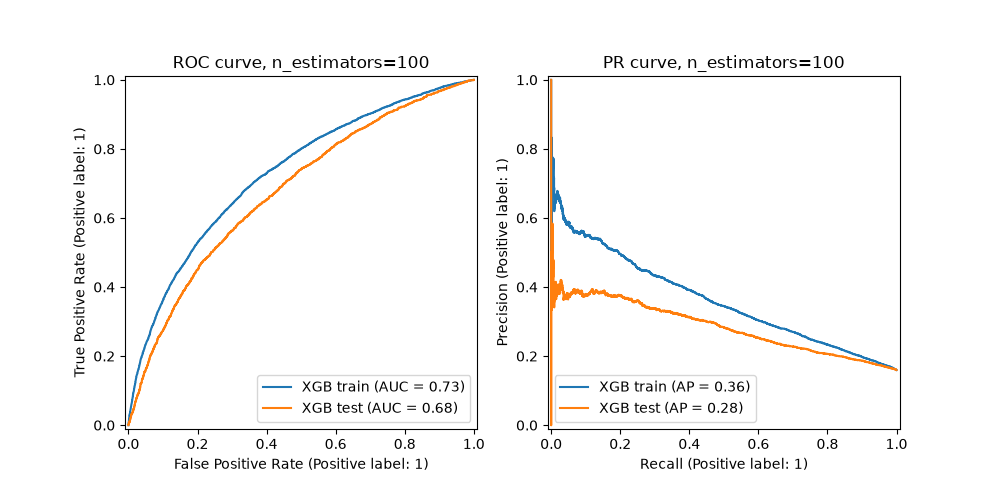

In [36]:
fig, ax = roc_pr_curve_plot(grid_search, X_cat_train, le.transform(y_cat_train), X_cat_test, le.transform(y_cat_test),
                            "XGB", f"n_estimators={grid_search.best_params_['classification__n_estimators']}")

`n_estimators=200` ($\approx \text{00:01:42}$):

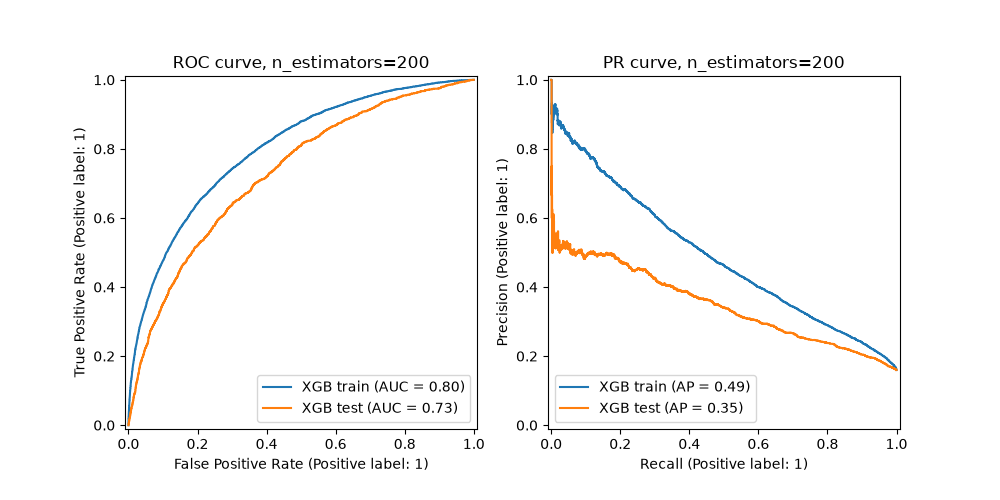

In [37]:
grid_params = {
    'classification__n_estimators': [200],
    'classification__learning_rate': [0.1],
    'classification__max_depth': [5]
}

data_path = f"data/models/xgb_model_imb_pipeline_gs_ne_200.sklm"
if compute_and_dump_data:
    grid_search = GridSearchCV(
        imb_pipeline, grid_params, cv = 5, n_jobs = 1, verbose = 3, error_score='raise'
    )

    grid_search.fit(X_cat_train, le.transform(y_cat_train))
    dump_model(data_path, grid_search)
else:
    grid_search = load_model(data_path)

fig, ax = roc_pr_curve_plot(grid_search, X_cat_train, le.transform(y_cat_train), X_cat_test, le.transform(y_cat_test),
                            "XGB", f"n_estimators={grid_search.best_params_['classification__n_estimators']}")

`n_estimators=400` ($\approx \text{00:03:04}$):

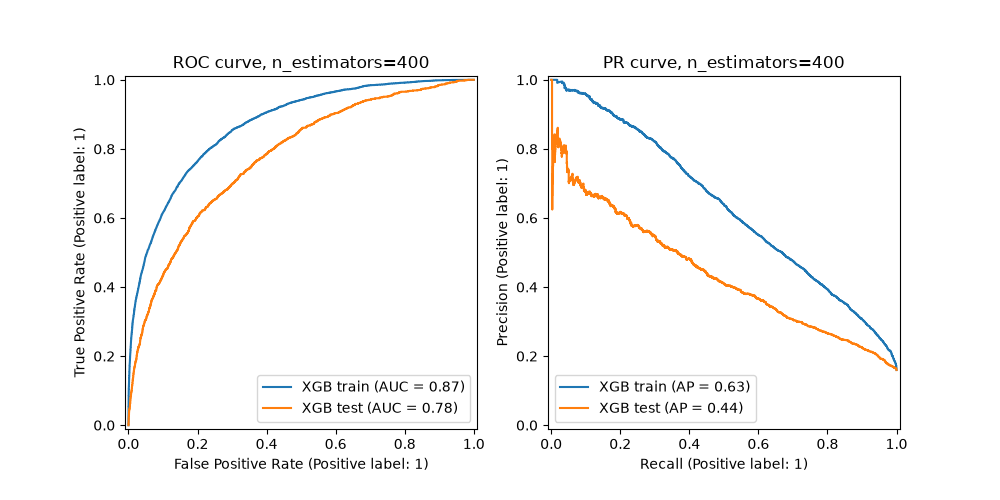

In [38]:
grid_params = {
    'classification__n_estimators': [400],
    'classification__learning_rate': [0.1],
    'classification__max_depth': [5]
}

data_path = f"data/models/xgb_model_imb_pipeline_gs_ne_400.sklm"
if compute_and_dump_data:
    grid_search = GridSearchCV(
        imb_pipeline, grid_params, cv = 5, n_jobs = 1, verbose = 3, error_score='raise'
    )

    grid_search.fit(X_cat_train, le.transform(y_cat_train))
    dump_model(data_path, grid_search)
else:
    grid_search = load_model(data_path)

fig, ax = roc_pr_curve_plot(grid_search, X_cat_train, le.transform(y_cat_train), X_cat_test, le.transform(y_cat_test),
                            "XGB", f"n_estimators={grid_search.best_params_['classification__n_estimators']}")

`n_estimators=800` ($\approx \text{00:05:13}$):

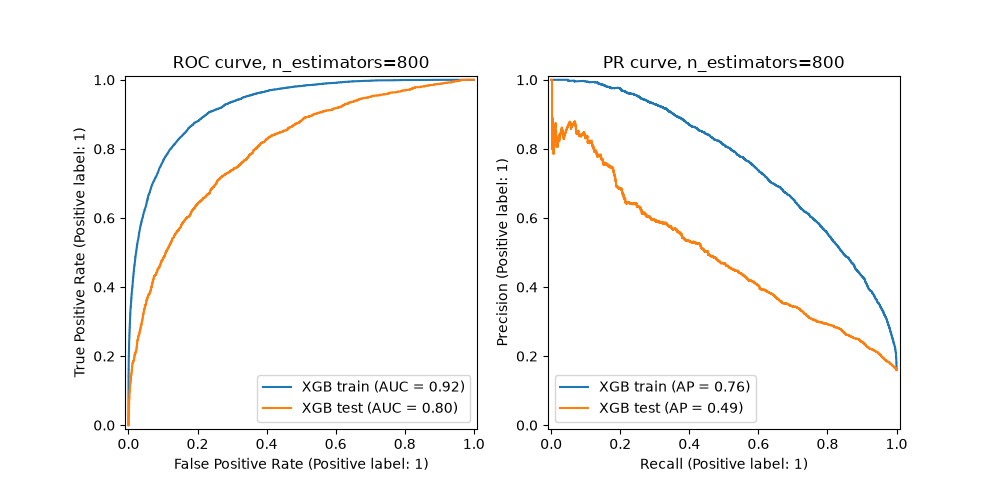

In [39]:
grid_params = {
    'classification__n_estimators': [800],
    'classification__learning_rate': [0.1],
    'classification__max_depth': [5]
}

data_path = f"data/models/xgb_model_imb_pipeline_gs_ne_800.sklm"
if compute_and_dump_data:
    grid_search = GridSearchCV(
        imb_pipeline, grid_params, cv = 5, n_jobs = 1, verbose = 3, error_score='raise'
    )

    grid_search.fit(X_cat_train, le.transform(y_cat_train))
    dump_model(data_path, grid_search)
else:
    grid_search = load_model(data_path)

fig, ax = roc_pr_curve_plot(grid_search, X_cat_train, le.transform(y_cat_train), X_cat_test, le.transform(y_cat_test),
                            "XGB", f"n_estimators={grid_search.best_params_['classification__n_estimators']}")

`n_estimators=1600` ($\approx \text{00:09:35}$):

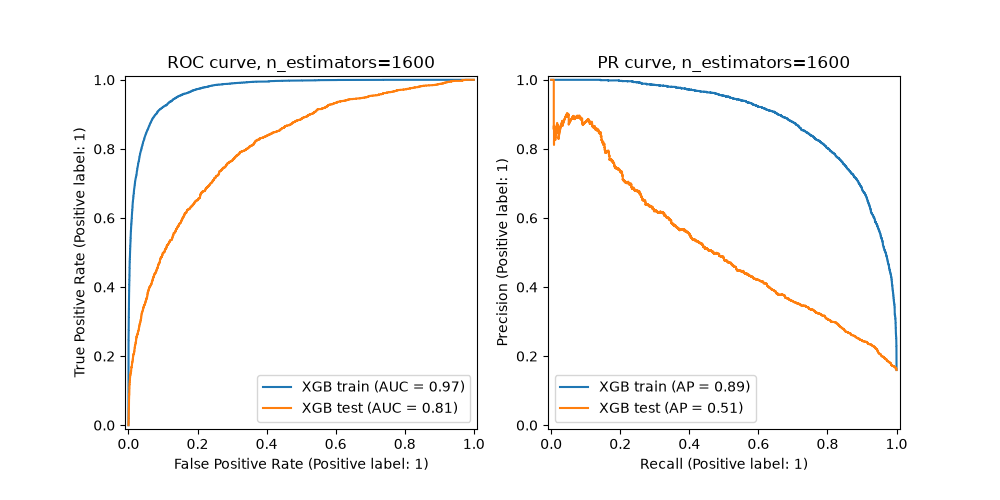

In [40]:
grid_params = {
    'classification__n_estimators': [1600],
    'classification__learning_rate': [0.1],
    'classification__max_depth': [5]
}

data_path = f"data/models/xgb_model_imb_pipeline_gs_ne_1600.sklm"
if compute_and_dump_data:
    grid_search = GridSearchCV(
        imb_pipeline, grid_params, cv = 5, n_jobs = 1, verbose = 3, error_score='raise'
    )

    grid_search.fit(X_cat_train, le.transform(y_cat_train))
    dump_model(data_path, grid_search)
else:
    grid_search = load_model(data_path)

fig, ax = roc_pr_curve_plot(grid_search, X_cat_train, le.transform(y_cat_train), X_cat_test, le.transform(y_cat_test),
                            "XGB", f"n_estimators={grid_search.best_params_['classification__n_estimators']}")

Очевидно, что модель переобучена.

In [41]:
params = json.dumps(grid_search.best_params_)
title = f"Oversampling + GridSearchCV (XGB),<br> best_params={params}"
classification_report_prettified(y_cat_test, le.inverse_transform(grid_search.predict(X_cat_test)), digits=14, target_names=['Rain tomorrow: No', 'Rain tomorrow: Yes'],
                                 title=title)

,precision,recall,f1-score,support
Rain tomorrow: No,0.87636089252991,0.97005130652667,0.92082908596670,8381
Rain tomorrow: Yes,0.63988522238164,0.27997489014438,0.38951965065502,1593
accuracy,0.85983557248847,0.85983557248847,0.85983557248847,0
macro avg,0.75812305745577,0.62501309833552,0.65517436831086,9974
weighted avg,0.83859211946532,0.85983557248847,0.83597086153804,9974


Оставим `n_estimators=200`.

In [42]:
xgb_best_params = {'n_estimators': 200}
xgb_best_params

{'n_estimators': 200}

Подбор `learning_rate` ($\approx \text{00:23:07}$):

In [43]:
grid_params = {
    'classification__n_estimators': [xgb_best_params['n_estimators']],
    'classification__learning_rate': np.linspace(0.05, 1.0, 20),
    'classification__max_depth': [5]
}
data_path = f"data/models/xgb_model_imb_pipeline_gs_learning_rate.sklm"
if compute_and_dump_data:
    grid_search = GridSearchCV(
        imb_pipeline, grid_params, cv = 5, n_jobs = 1, verbose = 3, error_score='raise'
    )

    grid_search.fit(X_cat_train, le.transform(y_cat_train))
    dump_model(data_path, grid_search)
else:
    grid_search = load_model(data_path)
grid_search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classification__learning_rate': array([0.05, ..., 0.95, 1. ]), 'classification__max_depth': [5], 'classification__n_estimators': [200]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``Gr

In [44]:
xgb_best_params['learning_rate'] = grid_search.best_params_['classification__learning_rate']
xgb_best_params

{'n_estimators': 200, 'learning_rate': np.float64(0.39999999999999997)}

Подбор `max_depth` ($\approx \text{00:13:12}$):

In [45]:
grid_params = {
    'classification__n_estimators': [xgb_best_params['n_estimators']],
    'classification__learning_rate': [xgb_best_params['learning_rate']],
    'classification__max_depth': [5, 6, 7, 8, 9, 10]
}
data_path = f"data/models/xgb_model_imb_pipeline_gs_max_depth.sklm"
if compute_and_dump_data:
    grid_search = GridSearchCV(
        imb_pipeline, grid_params, cv = 5, n_jobs = 1, verbose = 3, error_score='raise'
    )

    grid_search.fit(X_cat_train, le.transform(y_cat_train))
    dump_model(data_path, grid_search)
else:
    grid_search = load_model(data_path)
grid_search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classification__learning_rate': [np.float64(0....9999999999997)], 'classification__max_depth': [5, 6, ...], 'classification__n_estimators': [200]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly 

In [46]:
xgb_best_params['max_depth'] = grid_search.best_params_['classification__max_depth']
xgb_best_params

{'n_estimators': 200,
 'learning_rate': np.float64(0.39999999999999997),
 'max_depth': 5}

Тюнинг `max_delta_step` ($\approx \text{00:12:54}$):

In [47]:
grid_params = {
    'classification__n_estimators': [xgb_best_params['n_estimators']],
    'classification__learning_rate': [xgb_best_params['learning_rate']],
    'classification__max_depth': [xgb_best_params['max_depth']],
    'classification__max_delta_step': np.linspace(1, 10, 10)
}

data_path = f"data/models/xgb_model_imb_pipeline_gs_max_delta_step.sklm"
if compute_and_dump_data:
    grid_search = GridSearchCV(
        imb_pipeline, grid_params, cv = 5, n_jobs = 1, verbose = 3, error_score='raise'
    )

    grid_search.fit(X_cat_train, le.transform(y_cat_train))
    dump_model(data_path, grid_search)
else:
    grid_search = load_model(data_path)
grid_search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classification__learning_rate': [np.float64(0....9999999999997)], 'classification__max_delta_step': array([ 1., ...8., 9., 10.]), 'classification__max_depth': [5], 'classification__n_estimators': [200]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estim

In [48]:
xgb_best_params['max_delta_step'] = grid_search.best_params_['classification__max_delta_step']
xgb_best_params

{'n_estimators': 200,
 'learning_rate': np.float64(0.39999999999999997),
 'max_depth': 5,
 'max_delta_step': np.float64(3.0)}

,precision,recall,f1-score,support
Rain tomorrow: No,0.87479797435621,0.96873881398401,0.91937492922659,8381
Rain tomorrow: Yes,0.62193362193362,0.27055869428751,0.37707786526684,1593
accuracy,0.85722879486665,0.85722879486665,0.85722879486665,0
macro avg,0.74836579814492,0.61964875413576,0.64822639724671,9974
weighted avg,0.83441167864645,0.85722879486665,0.83276181283518,9974


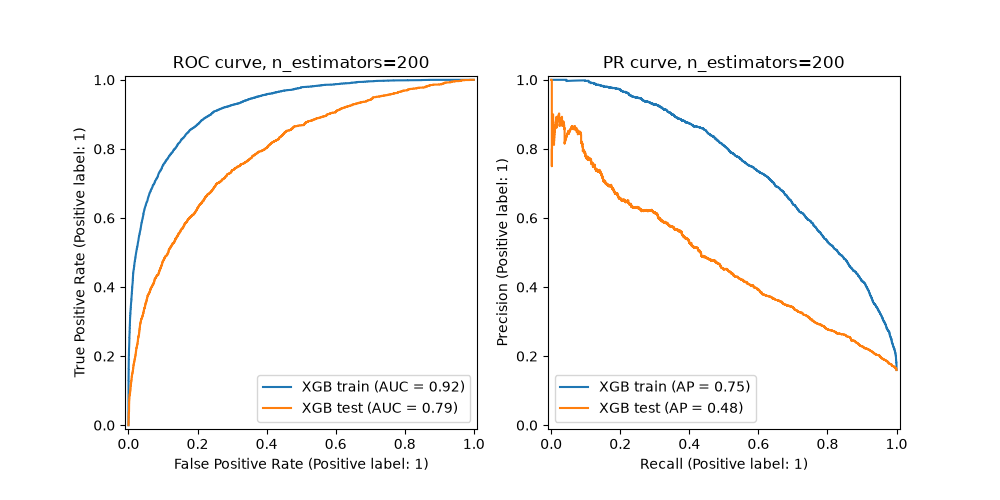

In [49]:
fig, ax = roc_pr_curve_plot(grid_search, X_cat_train, le.transform(y_cat_train), X_cat_test, le.transform(y_cat_test),
                            "XGB", f"n_estimators={grid_search.best_params_['classification__n_estimators']}")
params = json.dumps(grid_search.best_params_)
title = f"Oversampling + GridSearchCV (XGB),<br>best_params={params}"
classification_report_prettified(y_cat_test, le.inverse_transform(grid_search.predict(X_cat_test)), digits=14, target_names=['Rain tomorrow: No', 'Rain tomorrow: Yes'],
                                 title=title)

Тюнинг параметров регуляризации ($\approx \text{00:32:23}$):

In [50]:
grid_params = {
    'classification__n_estimators': [xgb_best_params['n_estimators']],
    'classification__learning_rate': [xgb_best_params['learning_rate']],
    'classification__max_depth': [xgb_best_params['max_depth']],
    'classification__max_delta_step': [xgb_best_params['max_delta_step']],
    'classification__gamma': np.arange(3),
    'classification__lambda': np.arange(3),
    'classification__alpha': np.arange(3),
}

data_path = f"data/models/xgb_model_imb_pipeline_gs_reg_params.sklm"
if compute_and_dump_data:
    grid_search = GridSearchCV(
        imb_pipeline, grid_params, cv = 5, n_jobs = 1, verbose = 3, error_score='raise'
    )

    grid_search.fit(X_cat_train, le.transform(y_cat_train))
    dump_model(data_path, grid_search)
else:
    grid_search = load_model(data_path)
grid_search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classification__alpha': array([0, 1, 2]), 'classification__gamma': array([0, 1, 2]), 'classification__lambda': array([0, 1, 2]), 'classification__learning_rate': [np.float64(0....9999999999997)], ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimat

In [51]:
for k, v in grid_search.best_params_.items():
    if type(v) == np.int64:
        grid_search.best_params_[k] = int(v)

xgb_best_params['gamma'] = grid_search.best_params_['classification__gamma']
xgb_best_params['lambda'] = grid_search.best_params_['classification__lambda']
xgb_best_params['alpha'] = grid_search.best_params_['classification__alpha']
xgb_best_params

{'n_estimators': 200,
 'learning_rate': np.float64(0.39999999999999997),
 'max_depth': 5,
 'max_delta_step': np.float64(3.0),
 'gamma': 2,
 'lambda': 2,
 'alpha': 2}

,precision,recall,f1-score,support
Rain tomorrow: No,0.87380722633215,0.97243765660422,0.92048791506664,8381
Rain tomorrow: Yes,0.64296754250386,0.26114249843063,0.37142857142857,1593
accuracy,0.85883296571085,0.85883296571085,0.85883296571085,0
macro avg,0.75838738441801,0.61679007751743,0.64595824324760,9974
weighted avg,0.83693860628619,0.85883296571085,0.83279475942041,9974


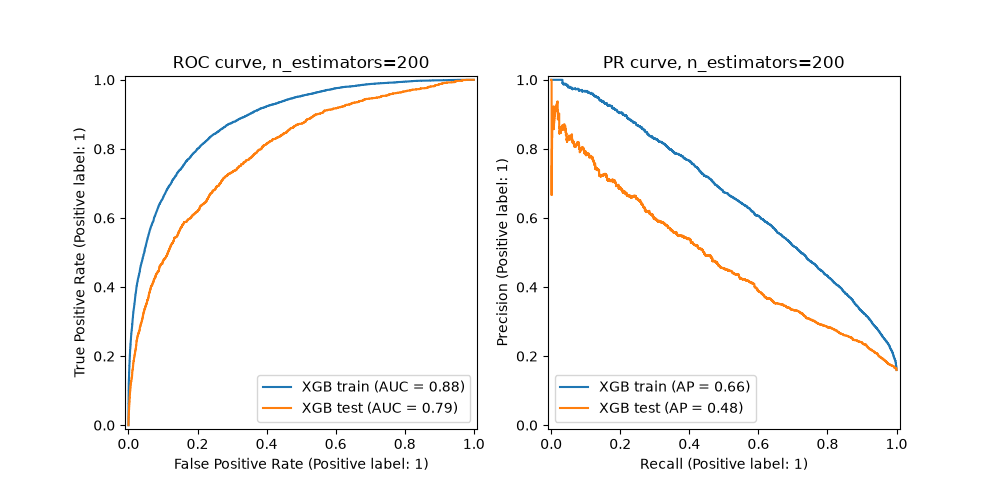

In [52]:
roc_pr_curve_plot(grid_search, X_cat_train, le.transform(y_cat_train), X_cat_test, le.transform(y_cat_test),
                  "XGB", f"n_estimators={grid_search.best_params_['classification__n_estimators']}")
params = json.dumps(grid_search.best_params_)
title = f"Oversampling + GridSearchCV (XGB),<br>best_params={params}"
classification_report_prettified(y_cat_test, le.inverse_transform(grid_search.predict(X_cat_test)), digits=14, target_names=['Rain tomorrow: No', 'Rain tomorrow: Yes'],
                                 title=title)

##### Пример с категориальными данными "как есть"

Для использования категориальных признаков в $XGBoost$ "as is" необходимо привести тип колонки к `category`. Для использования встроенного `One-Hot Encoder` необходимо задать параметр `max_cat_to_onehot`, установить значение, превышающее максимальную мощность среди категориальных признаков.

In [53]:
X_cat_train_1 = deepcopy(X_cat_train)
X_cat_test_1 = deepcopy(X_cat_test)

for col in X_cat_train_1.columns:
    if X_cat_train_1[col].dtype == 'str':
        X_cat_train_1[col] = X_cat_train_1[col].astype('category')
        X_cat_test_1[col] = X_cat_test_1[col].astype('category')

grid_params = {
    'classification__n_estimators': [xgb_best_params['n_estimators']],
    'classification__learning_rate': [xgb_best_params['learning_rate']],
    'classification__max_depth': [xgb_best_params['max_depth']],
    'classification__max_delta_step': [xgb_best_params['max_delta_step']],
    'classification__gamma': [xgb_best_params['gamma']],
    'classification__lambda': [xgb_best_params['lambda']],
    'classification__alpha': [xgb_best_params['alpha']],
}

data_path = f"data/models/xgb_model_imb_pipeline_gs_best_cat_as_is_max_cat_to_onehot_10000.sklm"
if compute_and_dump_data:
    xgb_model = XGBClassifier(objective='binary:logistic', random_state=777, enable_categorical=True, max_cat_to_onehot=10000)
    imb_pipeline_cat_as_is = ImbPipeline(steps=[('sampling', sm), ('classification', xgb_model)])

    grid_search = GridSearchCV(
        imb_pipeline_cat_as_is, grid_params, cv = 5, n_jobs = 1, verbose = 3, error_score='raise'
    )

    grid_search.fit(X_cat_train_1, le.transform(y_cat_train))
    dump_model(data_path, grid_search)
else:
    grid_search = load_model(data_path)
grid_search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classification__alpha': [2], 'classification__gamma': [2], 'classification__lambda': [2], 'classification__learning_rate': [np.float64(0....9999999999997)], ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``pred

,precision,recall,f1-score,support
Rain tomorrow: No,0.88950459935720,0.95764228612337,0.92231670880257,8381
Rain tomorrow: Yes,0.62670872765510,0.37413684871312,0.46855345911950,1593
accuracy,0.86444756366553,0.86444756366553,0.86444756366553,0
macro avg,0.75810666350615,0.66588956741825,0.69543508396104,9974
weighted avg,0.84753208846674,0.86444756366553,0.84984379354840,9974


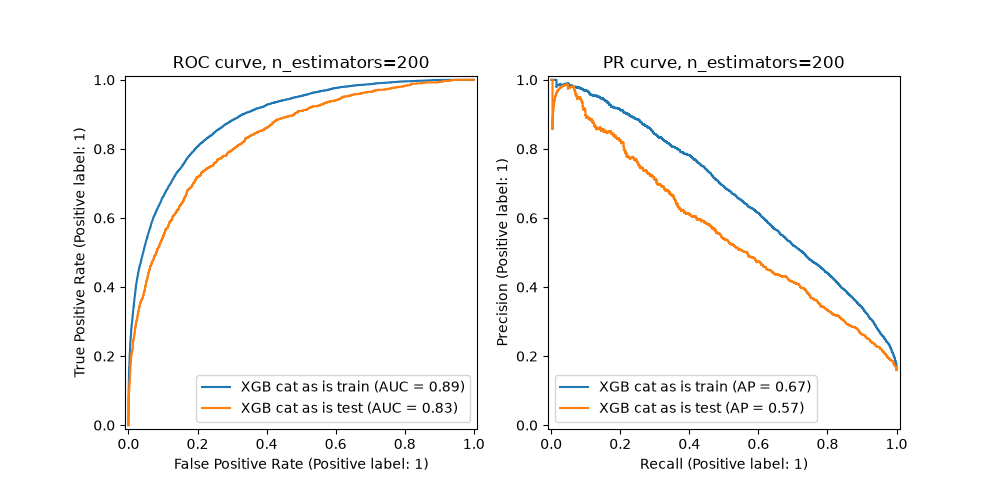

In [54]:
fig, ax = roc_pr_curve_plot(grid_search, X_cat_train_1, le.transform(y_cat_train), X_cat_test_1, le.transform(y_cat_test),
                            "XGB cat as is", f"n_estimators={grid_search.best_params_['classification__n_estimators']}")
params = json.dumps(grid_search.best_params_)
title = f"Oversampling + GridSearchCV (XGB cat as is),<br>best_params={params},<br>max_cat_to_onehot=10000"
classification_report_prettified(y_cat_test, le.inverse_transform(grid_search.predict(X_cat_test_1)), digits=14, target_names=['Rain tomorrow: No', 'Rain tomorrow: Yes'],
                                 title=title)

То же самое, но `max_cat_to_onehot` равен $1$:

In [55]:
data_path = f"data/models/xgb_model_imb_pipeline_gs_best_cat_as_is_max_cat_to_onehot_1.sklm"
if compute_and_dump_data:
    xgb_model = XGBClassifier(objective='binary:logistic', random_state=777, enable_categorical=True, max_cat_to_onehot=1)
    imb_pipeline_cat_as_is = ImbPipeline(steps=[('sampling', sm), ('classification', xgb_model)])

    grid_search = GridSearchCV(
        imb_pipeline_cat_as_is, grid_params, cv = 5, n_jobs = 1, verbose = 3, error_score='raise'
    )

    grid_search.fit(X_cat_train_1, le.transform(y_cat_train))
    dump_model(data_path, grid_search)
else:
    grid_search = load_model(data_path)
grid_search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classification__alpha': [2], 'classification__gamma': [2], 'classification__lambda': [2], 'classification__learning_rate': [np.float64(0....9999999999997)], ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``pred

,precision,recall,f1-score,support
Rain tomorrow: No,0.89664053751400,0.95537525354970,0.92507654092773,8381
Rain tomorrow: Yes,0.64176245210728,0.42059008160703,0.50815320439894,1593
accuracy,0.86996190094245,0.86996190094245,0.86996190094245,0
macro avg,0.76920149481064,0.68798266757836,0.71661487266334,9974
weighted avg,0.85593261791776,0.86996190094245,0.85848752196941,9974


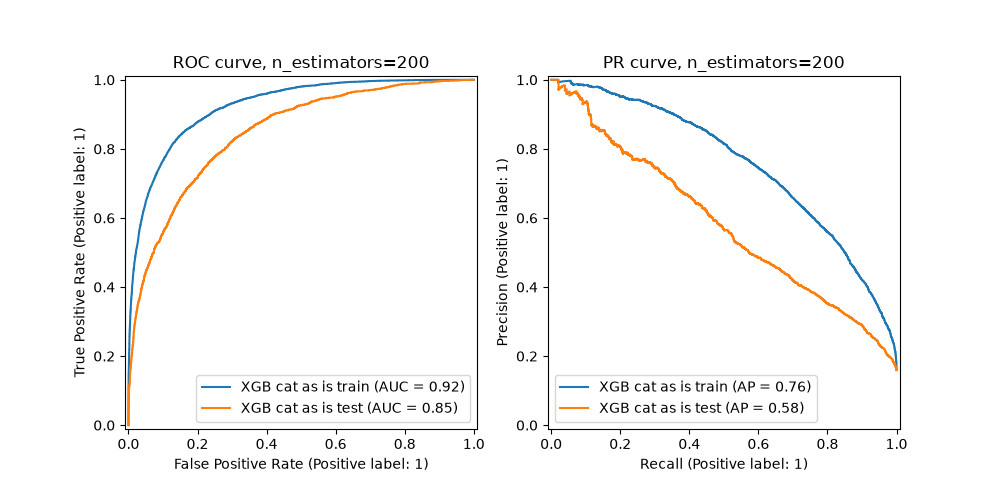

In [56]:
fig, ax = roc_pr_curve_plot(grid_search, X_cat_train_1, le.transform(y_cat_train), X_cat_test_1, le.transform(y_cat_test),
                            "XGB cat as is", f"n_estimators={grid_search.best_params_['classification__n_estimators']}")
params = json.dumps(grid_search.best_params_)
title = f"Oversampling + GridSearchCV (XGB cat as is),<br>best_params={params},<br>max_cat_to_onehot=1"
classification_report_prettified(y_cat_test, le.inverse_transform(grid_search.predict(X_cat_test_1)), digits=14, target_names=['Rain tomorrow: No', 'Rain tomorrow: Yes'],
                                 title=title)

На графиках видно, что разрыв по метрикам и «зазор» между кривыми вырос, что намекает на переобученность модели на обучающей выборке.

Обучим с теми же параметрами без сэмплирования:

In [57]:
grid_params = {
    'n_estimators': [xgb_best_params['n_estimators']],
    'learning_rate': [xgb_best_params['learning_rate']],
    'max_depth': [xgb_best_params['max_depth']],
    'max_delta_step': [xgb_best_params['max_delta_step']],
    'gamma': [xgb_best_params['gamma']],
    'lambda': [xgb_best_params['lambda']],
    'alpha': [xgb_best_params['alpha']],
}

data_path = f"data/models/xgb_model_imb_gs_best_cat_as_is_max_cat_to_onehot_1.sklm"
if compute_and_dump_data:
    xgb_model_imb = XGBClassifier(objective='binary:logistic', random_state=777, enable_categorical=True, max_cat_to_onehot=1)

    grid_search = GridSearchCV(
        xgb_model_imb, grid_params, cv = 5, n_jobs = 1, verbose = 3, error_score='raise'
    )

    grid_search.fit(X_cat_train_1, le.transform(y_cat_train))
    dump_model(data_path, grid_search)
else:
    grid_search = load_model(data_path)
grid_search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [2], 'gamma': [2], 'lambda': [2], 'learning_rate': [np.float64(0....9999999999997)], ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multipl

,precision,recall,f1-score,support
Rain tomorrow: No,0.8882198,0.9680229,0.9264059,8381
Rain tomorrow: Yes,0.6809524,0.3590709,0.4702014,1593
accuracy,0.8707640,0.8707640,0.8707640,0
macro avg,0.7845861,0.6635469,0.6983037,9974
weighted avg,0.8551161,0.8707640,0.8535431,9974


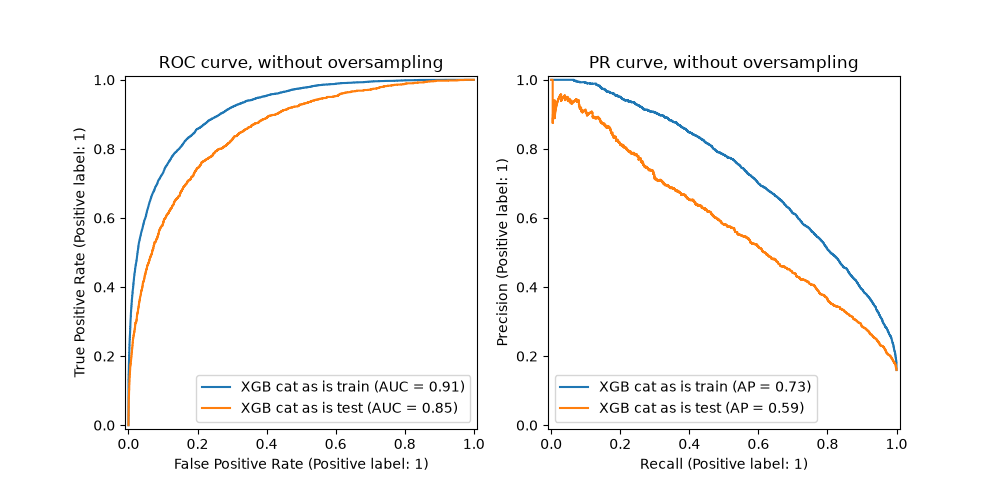

In [58]:
fig, ax = roc_pr_curve_plot(grid_search, X_cat_train_1, le.transform(y_cat_train), X_cat_test_1, le.transform(y_cat_test),
                            "XGB cat as is", f"without oversampling")
params = json.dumps(grid_search.best_params_)
title = f"GridSearchCV (best XGB cat as is),<br> best_params={params},<br>max_cat_to_onehot=1"
classification_report_prettified(y_cat_test, le.inverse_transform(grid_search.predict(X_cat_test_1)), digits=7, target_names=['Rain tomorrow: No', 'Rain tomorrow: Yes'],
                                 title=title)

В [Handle Imbalanced Dataset](https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html#handle-imbalanced-dataset) для улучшения предсказания модели, обученной на несбалансированном датасете, советуют потюнить `scale_pos_weight` и `max_delta_step`.
> `scale_pos_weight` [default=1]  
> - Control the balance of positive and negative weights, useful for unbalanced classes. A typical value to consider: `sum(negative instances) / sum(positive instances)`.

In [59]:
y_cat_train_vc = y_cat_train.value_counts()
y_cat_train_vc

RainTomorrow
No     33522
Yes     6374
Name: count, dtype: int64

In [60]:
scale_pos_weight = y_cat_train_vc['No'] / y_cat_train_vc['Yes']
scale_pos_weight

np.float64(5.259177910260433)

In [61]:
grid_params = {
    'n_estimators': [xgb_best_params['n_estimators']],
    'learning_rate': [xgb_best_params['learning_rate']],
    'max_depth': [xgb_best_params['max_depth']],
    'max_delta_step': [xgb_best_params['max_delta_step']],
    'gamma': [xgb_best_params['gamma']],
    'lambda': [xgb_best_params['lambda']],
    'alpha': [xgb_best_params['alpha']],
    'scale_pos_weight': [scale_pos_weight]
}

data_path = f"data/models/xgb_model_imb_gs_scale_pos_weight.sklm"
if compute_and_dump_data:
    grid_search = GridSearchCV(
        xgb_model_imb, grid_params, cv = 5, n_jobs = 1, verbose = 3, error_score='raise'
    )

    grid_search.fit(X_cat_train_1, le.transform(y_cat_train))
    dump_model(data_path, grid_search)
else:
    grid_search = load_model(data_path)
grid_search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [2], 'gamma': [2], 'lambda': [2], 'learning_rate': [np.float64(0....9999999999997)], ...}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multipl

,precision,recall,f1-score,support
Rain tomorrow: No,0.92974938319699,0.85431332776518,0.89043651287153,8381
Rain tomorrow: Yes,0.46282446106467,0.66038920276208,0.54423176409726,1593
accuracy,0.82334068578304,0.82334068578304,0.82334068578304,0
macro avg,0.69628692213083,0.75735126526363,0.71733413848440,9974
weighted avg,0.85517434800982,0.82334068578304,0.83514233152028,9974


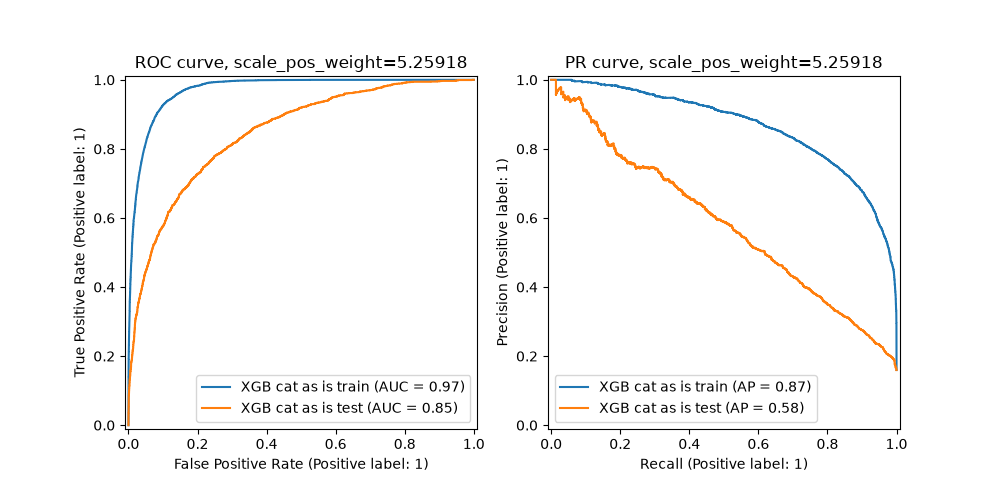

In [62]:
fig, ax = roc_pr_curve_plot(grid_search, X_cat_train_1, le.transform(y_cat_train), X_cat_test_1, le.transform(y_cat_test),
                            "XGB cat as is", f"scale_pos_weight={scale_pos_weight:.5f}")
params = json.dumps(grid_search.best_params_)
title = f"GridSearchCV (best XGB cat as is),<br> best_params={params},<br>scale_pos_weight={scale_pos_weight}"
classification_report_prettified(y_cat_test, le.inverse_transform(grid_search.predict(X_cat_test_1)), digits=14, target_names=['Rain tomorrow: No', 'Rain tomorrow: Yes'],
                                 title=title)

Overfitting is achieved :chart_with_upwards_trend:

In [63]:
xgb_best_params['alpha'] = grid_search.best_params_['alpha']
xgb_best_params

{'n_estimators': 200,
 'learning_rate': np.float64(0.39999999999999997),
 'max_depth': 5,
 'max_delta_step': np.float64(3.0),
 'gamma': 2,
 'lambda': 2,
 'alpha': 2}

##### Early Stopping

Гайд: [Early Stopping](https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html#early-stopping).

Обучим модель с ранней остановкой (параметр `early_stopping_rounds`). Для этого обучающую выборку поделим на новую обучающую и валидационную, выделим $12\%$ данных (от исходных $80\%$ это $9.6\%$ в итоге) в валидационный набор.

In [64]:
data_path = f"data/models/xgb_model_es.sklm"
if compute_and_dump_data:
    xgb_model_es = XGBClassifier(n_estimators=xgb_best_params['n_estimators'],
                                max_depth=xgb_best_params['max_depth'], 
                                max_delta_step=xgb_best_params['max_delta_step'],
                                learning_rate=xgb_best_params['learning_rate'],
                                gamma=xgb_best_params['gamma'],
                                alpha=xgb_best_params['alpha'],
                                reg_lambda=xgb_best_params['lambda'],
                                objective='binary:logistic',
                                scale_pos_weight=scale_pos_weight,
                                early_stopping_rounds=10,
                                enable_categorical=True)

    X_cat_eval, X_cat_train_1_reduced, y_cat_eval, y_cat_train_reduced = train_test_split(X_cat_train_1, y_cat_train, test_size = 0.12, random_state = 42)

    xgb_model_es.fit(X_cat_train_1_reduced, le.transform(y_cat_train_reduced), eval_set=[(X_cat_eval, le.transform(y_cat_eval))], verbose=0)
    dump_model(data_path, xgb_model_es)
else:
    xgb_model_es = load_model(data_path)
xgb_model_es

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",10
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [65]:
best_iteration = xgb_model_es.get_booster().best_iteration
y_cat_pred = xgb_model_es.predict(X_cat_test_1, iteration_range=(0, best_iteration + 1))
title = f"Best XGB cat as is, early_stopping_rounds=10"
classification_report_prettified(y_cat_test, le.inverse_transform(y_cat_pred), digits=14, target_names=['Rain tomorrow: No', 'Rain tomorrow: Yes'],
                                 title=title)

,precision,recall,f1-score,support
Rain tomorrow: No,0.90856079404467,0.87376208089727,0.89082172617237,8381
Rain tomorrow: Yes,0.44723092998955,0.53735091023227,0.48816652409467,1593
accuracy,0.82003208341688,0.82003208341688,0.82003208341688,0
macro avg,0.67789586201711,0.70555649556477,0.68949412513352,9974
weighted avg,0.83487937501120,0.82003208341688,0.82651154601298,9974


Согласно гайду использование кросс-валидации с ранней остановкой &ndash; идея не очень хорошая, так как на разных разбиениях данных модель будет содержать *разное количество слабых моделей*.

Пусть $eta$ &ndash; `early_stopping_rounds`, $iter$ &ndash; массив итераций.
По идее код должен реализовать следующие шаги (*Nested Cross-Validation*):
- Разбиваем выборку на обучающую и тестовую.
- Выделяем из обучающей или тестовой валидационный набор (`eval_set`).
- Внешний цикл кросс-валидации &ndash; разбиваем обучающую выборку на фолды (`outer fold`, $F_{outer}^i$) &ndash; `cv_outer`.
- Каждый $F_{outer}^i$ содержит обучающую `outer training set` и тестовую `outer test set` выборки 
- Для каждого фолда $F_{outer}^i$ запускается внутренний (*nested*) цикл кросс-валидации:
  + `outer training set` из $F_{outer}^i$ используется для кросс-валидации: он разбивается на внутренние фолды (`inner fold`, $F_{inner}^j$) &ndash; `cv_inner`
  + выполняем кросс-валидацию с `GridSearch`'ем по всем сочетаниям гиперпараметров модели на `cv_inner`
  + на $k_j$-й итерации проверяем, есть ли улучшение метрики за $eta$, нет &ndash; останавливаем обучение
  + запоминаем $k_j$: $iter_i = k_j$ &ndash; лучшая итерация на фолде $F_{outer}^i$
- Переобучаем модель с лучшими гиперпараметрами на `outer training set` из $F_{outer}^i$, `n_iterations` задаем равным $iter_i$
- Вычисляем метрики на `outer test set` из $F_{outer}^i$ (здесь можно дополнительно воспользоваться валидационным набором для вычисления кастомной метрики), запоминаем
- Переходим к $F_{outer}^{i + 1}$, повторяем шаги
- Поиск номера лучшей итерации &ndash; среднее по фолдам $F_{outer}^i$: $iter_{best} = mean \left( \sum\limits_{i=1}{iter_i} \right)$.
- Оценка качества модели &ndash; среднее по фолдам $F_{outer}^i$  

Финал: выполняем кросс-валидацию с использованием `n_iterations` равным $iter_{best}$, находим лучшие значения гиперпараметров.

Источники:
- [XGBoost GridSearchCV with early-stopping supported @ Kaggle](https://www.kaggle.com/code/yantiz/xgboost-gridsearchcv-with-early-stopping-supported/notebook)
- [Nested Cross-Validation for Machine Learning with Python](https://machinelearningmastery.com/nested-cross-validation-for-machine-learning-with-python/)
- [Nested versus non-nested cross-validation @ sklearn](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html)
- [Is it ok to determine early stopping using the validation set in 10-fold cross-validation? @ stackexchange](https://stats.stackexchange.com/a/56426)

### $CatBoost$

- [CatBoost tutorials @ GitHub](https://github.com/catboost/tutorials)

Установка:

```bash
uv pip install -U catboost
```

Будем работать с категориальными данными без кодирования.

In [66]:
import catboost as cb
print(f"Catboost version: {cb.__version__}")

Catboost version: 1.2.10


`iterations=1000` ($\approx \text{00:03:27}$):

In [67]:
from catboost import CatBoostClassifier

data_path = f"data/models/cb_model_i_1000.cbm"
if compute_and_dump_data:
    cb_model = CatBoostClassifier(iterations=1000, learning_rate=0.1, depth=6, cat_features=cat_cols)
    cb_model.fit(X_cat_train, y_cat_train, verbose=False, plot=True)
    cb_model.save_model(data_path)
else:
    cb_model = CatBoostClassifier()
    cb_model.load_model(data_path)
cb_model

CatBoostClassifier(depth=6, iterations=1000, learning_rate=0.1, loss_function='Logloss', verbose=0)

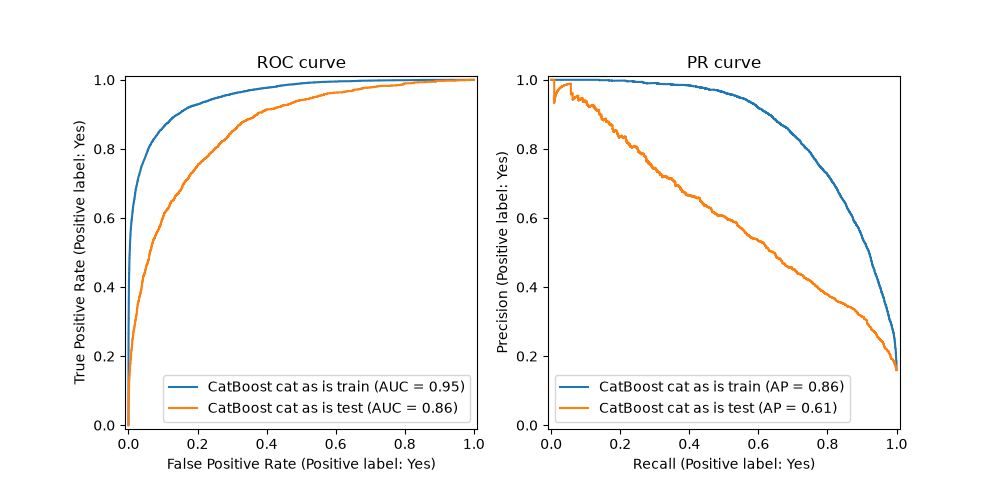

In [68]:
fig, ax = roc_pr_curve_plot(cb_model, X_cat_train, y_cat_train, X_cat_test, y_cat_test,
                            "CatBoost cat as is")

#### Класс `Pool`

$CatBoost$ использует специальный класс [`Pool`](https://catboost.ai/en/docs/concepts/python-reference_pool) для представления данных. Для создания объекта класса `Pool` необходимо указать признаки и целевую переменную:

In [69]:
from catboost import Pool

cat_cols = [var for var in X_cat_train.columns if X_cat_train[var].dtype == 'str']
train_data_cat = Pool(data=X_cat_train, label=y_cat_train, cat_features=cat_cols)
test_data_cat = Pool(data=X_cat_test, label=y_cat_test, cat_features=cat_cols)

> По умолчанию $CatBoost$ пишет различные метаданные при обучении модели в папку `catboost_info`, которые потом можно анализировать и визуализировать отдельно. Параметр [train_dir](https://catboost.ai/docs/en/references/training-parameters/output#train_dir) позволяет задать папку для вывода этих метаданных.  

[MetricVisualizer](https://catboost.ai/docs/en/concepts/python-reference_catboostipythonwidget) используется для визуализации этих данных автоматически в процессе обучения. Также данный класс может быть использован для визуализации ранее сохраненных данных обучения.

In [70]:
data_path = f"data/models/cb_model_i_1000_pool.cbm"
if compute_and_dump_data:
    cb_model = CatBoostClassifier(iterations=1000, learning_rate=0.1, depth=6, random_state=42, train_dir='data/catboost_metadata/first_train')
    cb_model.fit(train_data_cat, verbose=False, plot=True)
    cb_model.save_model(data_path)
else:
    cb_model = CatBoostClassifier()
    cb_model.load_model(data_path)
cb_model

CatBoostClassifier(depth=6, iterations=1000, learning_rate=0.1, loss_function='Logloss', random_seed=42, train_dir='data/catboost_metadata/first_train', verbose=0)

Пример кода для визуализации данных:

In [72]:
w = cb.MetricVisualizer('data/catboost_metadata/first_train')
w.start()

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

> Виджет может не отображаться.

Прямого доступа к графику на JS нет, но можно экспортировать в интерактивный HTML (с интегрированными ссылками на скрипты JS с CDN):

In [73]:
from ipywidgets.embed import embed_minimal_html
if compute_and_dump_data:
    embed_minimal_html('data/widgets/catboost_widget_first_train_export.html', views=w, title='CatBoost MetricVisualizer widget \"first_train\" export')

> HTML-экспорт виджета: [catboost_widget_first_train_export.html](data/catboost_widget_first_train_export.html).

Параметр [subdirs](https://catboost.ai/docs/en/concepts/python-reference_catboostipythonwidget#subdirs) со значением `True` позволяет считать данные из подпапок и визуализировать несколько экспериментов.
> При использовании `objective='CrossEntropy'` необходимо закодировать явно таргет, поэтому обернем еще раз в `Pool` выборки с закодированным таргетом.

In [74]:
train_data_cat_te = Pool(data=X_cat_train, label=le.transform(y_cat_train), cat_features=cat_cols)
test_data_cat_te = Pool(data=X_cat_test, label=le.transform(y_cat_test), cat_features=cat_cols)

In [75]:
data_path = f"data/models/cb_model_i_200_pool.cbm"
if compute_and_dump_data:
    cb_model_1 = CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, random_state=42, objective='CrossEntropy', train_dir='data/catboost_metadata/second_train')
    cb_model_1.fit(train_data_cat_te, verbose=False, plot=True)
    cb_model_1.save_model(data_path)
else:
    cb_model_1 = CatBoostClassifier()
    cb_model_1.load_model(data_path)
cb_model_1
    

CatBoostClassifier(depth=6, iterations=200, learning_rate=0.1, loss_function='CrossEntropy', random_seed=42, train_dir='data/catboost_metadata/second_train', verbose=0)

Визуализация двух экспериментов (две «вкладки» &ndash; `Logloss` и `CrossEntropy`):

In [76]:
w = cb.MetricVisualizer(['data/catboost_metadata/first_train', 'data/catboost_metadata/second_train'])
w.start()

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

In [77]:
if compute_and_dump_data:
    embed_minimal_html('data/widgets/catboost_widget_double_export.html', views=w, title='CatBoost MetricVisualizer widget \"double\" export')

> HTML-экспорт виджета: [catboost_widget_double_export.html](data/catboost_widget_double_export.html).

Данные, сконвертированные в `Pool`, не получится обратно преобразовать в датафрейм. Модифицируем `roc_pr_curve_plot` для построения $ROC$ и $PR$ кривых не из данных модели-предсказателя (`.from_estimator()`), а из непосредственно предсказаний вероятности (`.from_predictions()`):

In [78]:
def roc_pr_curve_plot_from_predictions(model, y_train, y_test, model_name, param_str=''):
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))

    if len(param_str) > 0:
        param_str = ", " + param_str
    
    y_train_true = y_train
    y_test_true = y_test
    
    # If type is CatBoost.Pool, extract labels
    if type(y_train) is cb.Pool:  
        y_train_true = y_train.get_label()
        y_test_true = y_test.get_label()
    
    y_train_pred = model.predict_proba(y_train)[:, 1]
    y_test_pred = model.predict_proba(y_test)[:, 1]

    display = RocCurveDisplay.from_predictions(
        y_train_true, y_train_pred, name=f"{model_name} train", ax=ax[0]
    )
    display = RocCurveDisplay.from_predictions(
        y_test_true, y_test_pred, name=f"{model_name} test", ax=ax[0]
    )
    ax[0].set_title(f"ROC curve{param_str}")
    ax[0].set_aspect('equal', adjustable='box')

    display = PrecisionRecallDisplay.from_predictions(
        y_train_true, y_train_pred, name=f"{model_name} train", ax=ax[1]
    )
    display = PrecisionRecallDisplay.from_predictions(
        y_test_true, y_test_pred, name=f"{model_name} test", ax=ax[1]
    )
    ax[1].set_title(f"PR curve{param_str}")
    ax[1].set_aspect('equal', adjustable='box')
    return fig, ax

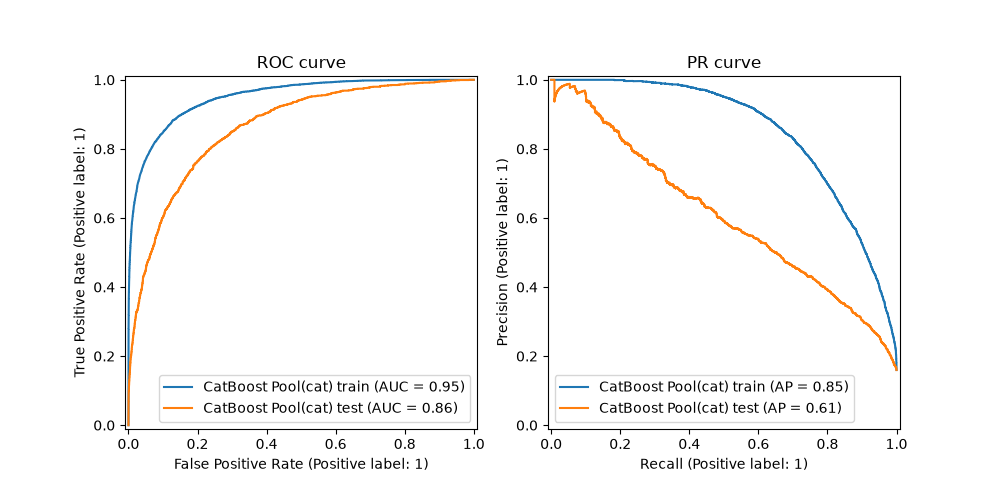

In [79]:
fig, ax = roc_pr_curve_plot_from_predictions(cb_model, train_data_cat_te, test_data_cat_te, "CatBoost Pool(cat)")

#### Важность признаков

$CatBoost$ позволяет оценить важность признаков с помощью атрибута `feature_importances_`:

In [80]:
importances = cb_model.get_feature_importance(prettified=True)
importances

,Feature Id,Importances
0,Humidity3pm,15.188174
1,Pressure3pm,8.474246
2,Location,7.789326
3,Pressure9am,6.972850
4,WindGustSpeed,5.766363
5,MinTemp,5.071391
6,Temp3pm,4.758178
7,Temp9am,4.462401
8,MaxTemp,4.075890
9,WindDir3pm,4.043276


#### Работа $CatBoost$ с категориальными данными

Согласно гайду [Speeding up the training](https://catboost.ai/en/docs/concepts/speed-up-training) есть несколько стратегий обработки категориальных признаков, производительность сильно зависит от значений различных параметров.
- Как и в $XGBoost$, можно увеличить значение параметра `one_hot_max_size`, явно указав использование `One-Hot Encoder`. Подходит для признаков с низкой мощностью.
- Для признаков с высокой мощностью лучше не использовать `One-Hot Encoder`. Под капотом используются счетчики для категориальных признаков. Подробнее описано в статье [CatBoost: unbiased boosting with categorical features](https://arxiv.org/pdf/1706.09516).

Есть [бенчмарк на гите](https://github.com/catboost/benchmarks/tree/master/quality_benchmarks), на который ссылается статья. В данном бенче $CatBoost$ сравнивают с $LightGBM$, $XGBoost$, $H2O$. В репе есть `cat_counter.py` с реализацией *"Class for calculating counter values"*.

В issue [[CPU] Training is excruciatingly slow for CatBoostClassifier](https://github.com/catboost/catboost/issues/1859) жалоба на низкую производительность обучения модели на CPU: $34000$ строк, $22$ категориальных признака и таргет с $75$ классами. В ответе разработчик пишет, что это порождает $75 \cdot 22 \cdot 3 = 4950$ новых признаков.

Аналогичный ответ дают в [why model file is large and training slower than xgboost and lightgbm](https://github.com/catboost/catboost/issues/960). Есть issue с медленным обучением на GPU: [Catboost VERY slow - RTX 3090 & 2080 TI not beeing utilized fully](https://github.com/catboost/catboost/issues/2359).

Также есть [устаревший бенчмарк производительности обучения](https://github.com/catboost/benchmarks/tree/master/training_speed).

Вспомогательный метод для рендера `Markdown` ссылки на HTML виджет:

In [81]:
from IPython.display import Markdown

def render_widget_export_link(train_name, font_size=13):
    m = Markdown(f"<div style='font-size: {font_size}pt;'><br>\n\n> HTML-экспорт виджета: [catboost_widget_{train_name}_export.html](data/widgets/catboost_widget_{train_name}_export.html).\n\n</div>")
    display(m)

def render_styled_markdown(text_md, font_size=13):
    m = Markdown(f"<div style='font-size: {font_size}pt;'><br>\n\n>{text_md}\n\n</div>")
    display(m)

##### Параметр `one_hot_max_size`

In [82]:
train_name = 'one_hot_max_size'
train_dir = f'data/catboost_metadata/{train_name}'

data_path = f"data/models/cb_model_{train_name}.cbm"
if compute_and_dump_data:
    cb_model = CatBoostClassifier(iterations=1000, learning_rate=0.1, depth=6, one_hot_max_size=10000, random_state=42, train_dir=train_dir)
    cb_model.fit(train_data_cat, verbose=False, plot=False)
    w = cb.MetricVisualizer(train_dir)
    w.start()
    embed_minimal_html(f'data/widgets/catboost_widget_{train_name}_export.html', views=w, title=f'CatBoost MetricVisualizer widget \"{train_name}\" export')
    cb_model.save_model(data_path)
else:
    cb_model = CatBoostClassifier()
    cb_model.load_model(data_path)
    w = cb.MetricVisualizer(train_dir)
    w.start()

render_widget_export_link(train_name)

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

<div style='font-size: 13pt;'><br>

> HTML-экспорт виджета: [catboost_widget_one_hot_max_size_export.html](data/widgets/catboost_widget_one_hot_max_size_export.html).

</div>

##### `pandas.Categorical`

В гайде [Speeding up the training](https://catboost.ai/en/docs/concepts/speed-up-training#pandas-instead-of-objects) советуют вместо типа `object` (`pandas` $<3.0.0$) или `str` (`pandas` $\geq 3.0.0$) использовать тип `pandas.Categorical`.

In [83]:
cat_cols_cb = [var for var in X_cat_train.columns if X_cat_train[var].dtype == 'str']
X_cat_train_cb = deepcopy(X_cat_train)
X_cat_test_cb = deepcopy(X_cat_test)

for col in cat_cols_cb:
    X_cat_train_cb[col] = pd.Categorical(X_cat_train_cb[col])
    X_cat_test_cb[col] = pd.Categorical(X_cat_test_cb[col])

train_data_cat_cb = Pool(data=X_cat_train_cb, label=y_cat_train, cat_features=cat_cols_cb)
test_data_cat_cb = Pool(data=X_cat_test, label=y_cat_test, cat_features=cat_cols_cb)

train_name = 'pd_categorical'
train_dir = f'data/catboost_metadata/{train_name}'

data_path = f"data/models/cb_model_{train_name}.cbm"
if compute_and_dump_data:
    cb_model = CatBoostClassifier(iterations=1000, learning_rate=0.1, depth=6, one_hot_max_size=10000, random_state=42, train_dir=train_dir)
    cb_model.fit(train_data_cat_cb, verbose=False, plot=False)
    w = cb.MetricVisualizer(train_dir)
    w.start()
    embed_minimal_html(f'data/widgets/catboost_widget_{train_name}_export.html', views=w, title=f'CatBoost MetricVisualizer widget \"{train_name}\" export')
    cb_model.save_model(data_path)
else:
    cb_model = CatBoostClassifier()
    cb_model.load_model(data_path)
    w = cb.MetricVisualizer(train_dir)
    w.start()

render_widget_export_link(train_name)

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

<div style='font-size: 13pt;'><br>

> HTML-экспорт виджета: [catboost_widget_pd_categorical_export.html](data/widgets/catboost_widget_pd_categorical_export.html).

</div>

##### `pandas.DataFrame` $\rightarrow$ `numpy array`

В гайде [Speeding up the training](https://catboost.ai/en/docs/concepts/speed-up-training#numpy-instead-of-pandas) советуют вместо датафрейма использовать `numpy` массивы.

In [84]:
train_data_cat_cb = Pool(data=X_cat_train.to_numpy(), label=y_cat_train.to_numpy(), cat_features=cat_cols_cb, feature_names=X_cat_train.columns.to_list())
test_data_cat_cb = Pool(data=X_cat_test.to_numpy(), label=y_cat_test.to_numpy(), cat_features=cat_cols_cb, feature_names=X_cat_train.columns.to_list())

train_name = 'to_numpy'
train_dir = f'data/catboost_metadata/{train_name}'

data_path = f"data/models/cb_model_{train_name}.cbm"
if compute_and_dump_data:
    cb_model = CatBoostClassifier(iterations=1000, learning_rate=0.1, depth=6, one_hot_max_size=10000, random_state=42, train_dir=train_dir)
    cb_model.fit(train_data_cat_cb, verbose=False, plot=False)
    w = cb.MetricVisualizer(train_dir)
    w.start()
    embed_minimal_html(f'data/widgets/catboost_widget_{train_name}_export.html', views=w, title=f'CatBoost MetricVisualizer widget \"{train_name}\" export')
    cb_model.save_model(data_path)
else:
    cb_model = CatBoostClassifier()
    cb_model.load_model(data_path)
    w = cb.MetricVisualizer(train_dir)
    w.start()

render_widget_export_link(train_name)

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

<div style='font-size: 13pt;'><br>

> HTML-экспорт виджета: [catboost_widget_to_numpy_export.html](data/widgets/catboost_widget_to_numpy_export.html).

</div>

##### GPU

В качестве `task_type` зададим `GPU`. `one_hot_max_size` в режиме вычислений `GPU` [ограничен](https://catboost.ai/docs/en/concepts/speed-up-training#one-hot-encoding) максимальным значением $255$.
> Вернем в качестве обучающей выборки `Pool`-объект `train_data_cat`.  

Время вычислений $\approx \text{00:00:36}$.

In [86]:
train_name = 'gpu_one_hot_max_size'
train_dir = f'data/catboost_metadata/{train_name}'

data_path = f"data/models/cb_model_{train_name}.cbm"
if compute_and_dump_data:
    cb_model = CatBoostClassifier(iterations=1000, learning_rate=0.1, depth=6, one_hot_max_size=255, random_state=42, task_type='GPU', train_dir=train_dir)
    cb_model.fit(train_data_cat, verbose=False, plot=False)
    w = cb.MetricVisualizer(train_dir)
    w.start()
    embed_minimal_html(f'data/widgets/catboost_widget_{train_name}_export.html', views=w, title=f'CatBoost MetricVisualizer widget \"{train_name}\" export')
    cb_model.save_model(data_path)
else:
    cb_model = CatBoostClassifier()
    cb_model.load_model(data_path)
    w = cb.MetricVisualizer(train_dir)
    w.start()

render_widget_export_link(train_name)

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

<div style='font-size: 13pt;'><br>

> HTML-экспорт виджета: [catboost_widget_gpu_one_hot_max_size_export.html](data/widgets/catboost_widget_gpu_one_hot_max_size_export.html).

</div>

`one_hot_max_size=1`. Время вычислений $\approx \text{00:00:49}$.

In [87]:
train_name = 'gpu_cat_as_is'
train_dir = f'data/catboost_metadata/{train_name}'

data_path = f"data/models/cb_model_{train_name}.cbm"
if compute_and_dump_data:
    cb_model = CatBoostClassifier(iterations=1000, learning_rate=0.1, depth=6, one_hot_max_size=1, random_state=42, task_type='GPU', train_dir=train_dir)
    cb_model.fit(train_data_cat, verbose=False, plot=False)
    w = cb.MetricVisualizer(train_dir)
    w.start()
    embed_minimal_html(f'data/widgets/catboost_widget_{train_name}_export.html', views=w, title=f'CatBoost MetricVisualizer widget \"{train_name}\" export')
    cb_model.save_model(data_path)
else:
    cb_model = CatBoostClassifier()
    cb_model.load_model(data_path)
    w = cb.MetricVisualizer(train_dir)
    w.start()

render_widget_export_link(train_name)

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

<div style='font-size: 13pt;'><br>

> HTML-экспорт виджета: [catboost_widget_gpu_cat_as_is_export.html](data/widgets/catboost_widget_gpu_cat_as_is_export.html).

</div>

> Выигрыш в скорости в обоих случаях не обнаружен, 16 ГБ VRAM, очевидно, не хватает.

Все параметры модели:

In [88]:
import json
print(json.dumps(cb_model.get_all_params(), indent=4))

{
    "nan_mode": "Min",
    "gpu_ram_part": 0.95,
    "eval_metric": "Logloss",
    "combinations_ctr": [
        "Borders:CtrBorderCount=15:CtrBorderType=Uniform:TargetBorderCount=1:TargetBorderType=MinEntropy:Prior=0/1:Prior=0.5/1:Prior=1/1",
        "FeatureFreq:CtrBorderCount=15:CtrBorderType=Median:Prior=0/1"
    ],
    "iterations": 1000,
    "fold_permutation_block": 64,
    "leaf_estimation_method": "Newton",
    "observations_to_bootstrap": "TestOnly",
    "random_score_type": "NormalWithModelSizeDecrease",
    "counter_calc_method": "SkipTest",
    "grow_policy": "SymmetricTree",
    "penalties_coefficient": 1,
    "boosting_type": "Ordered",
    "ctr_history_unit": "Sample",
    "feature_border_type": "GreedyLogSum",
    "bayesian_matrix_reg": 0.1000000015,
    "one_hot_max_size": 1,
    "devices": "-1",
    "eval_fraction": 0,
    "pinned_memory_bytes": "104857600",
    "force_unit_auto_pair_weights": false,
    "l2_leaf_reg": 3,
    "random_strength": 1,
    "rsm": 1,
   

#### Grid search

В $CatBoost$ есть собственный grid search: метод [`grid_search`](https://catboost.ai/en/docs/concepts/python-reference_catboostclassifier_grid_search). Из обучающей выборки $6.25\%$ ($5\%$ от $X$) выделим в валидационный набор, то есть в обучающей останется $75\%$.

##### Тюнинг параметра регуляризации `depth`

> Сочетание `verbose=False` в конструкторе модели и `verbose=False, plot=True` в `grid_search` не отключает полностью вывод информации в консоль: все равно осуществляется вывод информации о `bestTest`, `bestIteration`, `Training on fold [x/y]`. При этом нельзя одновременно задавать параметры `logging_level` и `verbose` в конструкторе модели, например. Сочетание `logging_level='Silent'` в конструкторе модели и `verbose=False, plot=True` в `grid_search` убирают вывод лога в консоль. См. [CatBoost -- suppressing iteration results in a grid search @ stackoverflow](https://stackoverflow.com/a/67651086).

In [89]:
def save_dict_to_json(path: str, d: dict):
    with open(path, 'w') as f:
        json.dump(d, f, indent=4)

def load_dict_from_json(path: str) -> dict:
    d = None
    with open(path, 'r') as f:
        d = json.load(f)
    return d

Время вычислений: $\approx \text{00:00:52}$.

In [90]:
cb_model = CatBoostClassifier(random_state=0, logging_level='Silent')

cb_grid_params = {
    'iterations': [1000],
    'learning_rate': [0.1],
    'depth': [4, 6, 8, 10],
    'one_hot_max_size': [10000],
    'early_stopping_rounds': [10]
}

train_name = 'grid_search_depth'
train_dir = f'data/catboost_metadata/{train_name}'

data_path = f"data/models/cb_model_{train_name}.cbm"
gs_dict_path = f"data/models/cb_model_{train_name}_result.json"
if compute_and_dump_data:
    cb_model = CatBoostClassifier(random_state=42, train_dir=train_dir)
    cb_grid_search_result = cb_model.grid_search(cb_grid_params, train_data_cat, cv=5, train_size=0.9375, verbose=False, plot=False)
    w = cb.MetricVisualizer(train_dir)
    w.start()
    embed_minimal_html(f'data/widgets/catboost_widget_{train_name}_export.html', views=w, title=f'CatBoost MetricVisualizer widget \"{train_name}\" export')
    cb_model.save_model(data_path)
    save_dict_to_json(gs_dict_path, cb_grid_search_result)
else:
    cb_model = CatBoostClassifier()
    cb_model.load_model(data_path)
    w = cb.MetricVisualizer(train_dir)
    w.start()
    cb_grid_search_result = load_dict_from_json(gs_dict_path)

render_widget_export_link(train_name)

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

<div style='font-size: 13pt;'><br>

> HTML-экспорт виджета: [catboost_widget_grid_search_depth_export.html](data/widgets/catboost_widget_grid_search_depth_export.html).

</div>

Выведем полученные результаты `.grid_search()` в виде HTML-спойлера с форматированным JSON'ом:

In [91]:
from IPython.display import HTML
display(HTML(f"<details style='font-size: 13pt;'><summary>grid_search_result output (спойлер)</summary><pre>{json.dumps(cb_grid_search_result, indent=4)}</pre></details>"))

In [92]:
cb_grid_search_result['params']

{'depth': 6,
 'od_wait': 10,
 'one_hot_max_size': 10000,
 'learning_rate': 0.1,
 'iterations': 1000}

In [93]:
y_cat_pred = cb_model.predict(X_cat_test)
cr = classification_report_prettified(y_cat_test, y_cat_pred, digits=14, target_names=['Rain tomorrow: No', 'Rain tomorrow: Yes'],
                                      title=f"CatBoost grid_search<br>params={cb_grid_search_result['params']}")
cr

,precision,recall,f1-score,support
Rain tomorrow: No,0.88976550515012,0.96885813148789,0.92762894842063,8381
Rain tomorrow: Yes,0.69221698113208,0.36848713119900,0.48095043015158,1593
accuracy,0.87296972127532,0.87296972127532,0.87296972127532,0
macro avg,0.79099124314110,0.66867263134344,0.70428968928610,9974
weighted avg,0.85821399133813,0.87296972127532,0.85628757288398,9974


In [94]:
cb_best_params = deepcopy(cb_grid_search_result['params'])
cb_best_params

{'depth': 6,
 'od_wait': 10,
 'one_hot_max_size': 10000,
 'learning_rate': 0.1,
 'iterations': 1000}

##### Тюнинг параметра регуляризации `l2_leaf_reg`

> Без вывода лога обучения: `logging_level='Silent'`.  

Время вычислений: $\approx \text{00:01:08}$.

In [95]:
cb_grid_params = {
    'iterations': [cb_best_params['iterations']],
    'learning_rate': [cb_best_params['learning_rate']],
    'one_hot_max_size': [cb_best_params['one_hot_max_size']],
    'depth': [cb_best_params['depth']],
    'od_wait': [cb_best_params['od_wait']],
    'l2_leaf_reg': range(1, 17, 2)
}

train_name = 'grid_search_l2_leaf_reg'
train_dir = f'data/catboost_metadata/{train_name}'

data_path = f"data/models/cb_model_{train_name}.cbm"
gs_dict_path = f"data/models/cb_model_{train_name}_result.json"
if compute_and_dump_data:
    cb_model = CatBoostClassifier(random_state=42, train_dir=train_dir, logging_level='Silent')
    cb_grid_search_result = cb_model.grid_search(cb_grid_params, train_data_cat, cv=5, train_size=0.9375, verbose=False, plot=False)
    w = cb.MetricVisualizer(train_dir)
    w.start()
    embed_minimal_html(f'data/widgets/catboost_widget_{train_name}_export.html', views=w, title=f'CatBoost MetricVisualizer widget \"{train_name}\" export')
    cb_model.save_model(data_path)
    save_dict_to_json(gs_dict_path, cb_grid_search_result)
else:
    cb_model = CatBoostClassifier()
    cb_model.load_model(data_path)
    w = cb.MetricVisualizer(train_dir)
    w.start()
    cb_grid_search_result = load_dict_from_json(gs_dict_path)
    
render_widget_export_link(train_name)

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

<div style='font-size: 13pt;'><br>

> HTML-экспорт виджета: [catboost_widget_grid_search_l2_leaf_reg_export.html](data/widgets/catboost_widget_grid_search_l2_leaf_reg_export.html).

</div>

In [96]:
cb_best_params['l2_leaf_reg'] = cb_grid_search_result['params']['l2_leaf_reg']
cb_best_params

{'depth': 6,
 'od_wait': 10,
 'one_hot_max_size': 10000,
 'learning_rate': 0.1,
 'iterations': 1000,
 'l2_leaf_reg': 13}

##### Тюнинг параметра регуляризации `learning_rate`

Время вычислений: $\approx \text{00:02:07}$.

In [97]:
cb_grid_params = {
    'iterations': [cb_best_params['iterations']],
    'learning_rate': [cb_best_params['learning_rate']],
    'one_hot_max_size': [cb_best_params['one_hot_max_size']],
    'depth': [cb_best_params['depth']],
    'od_wait': [cb_best_params['od_wait']],
    'l2_leaf_reg': [cb_best_params['od_wait']],
    'learning_rate': np.arange(0.01, 0.11, 0.01)
}

train_name = 'grid_search_learning_rate'
train_dir = f'data/catboost_metadata/{train_name}'

data_path = f"data/models/cb_model_{train_name}.cbm"
gs_dict_path = f"data/models/cb_model_{train_name}_result.json"
if compute_and_dump_data:
    cb_model = CatBoostClassifier(random_state=42, train_dir=train_dir, logging_level='Silent')
    cb_grid_search_result = cb_model.grid_search(cb_grid_params, train_data_cat, cv=5, train_size=0.9375, verbose=False, plot=False)
    w = cb.MetricVisualizer(train_dir)
    w.start()
    embed_minimal_html(f'data/widgets/catboost_widget_{train_name}_export.html', views=w, title=f'CatBoost MetricVisualizer widget \"{train_name}\" export')
    cb_model.save_model(data_path)
    save_dict_to_json(gs_dict_path, cb_grid_search_result)
else:
    cb_model = CatBoostClassifier()
    cb_model.load_model(data_path)
    w = cb.MetricVisualizer(train_dir)
    w.start()
    cb_grid_search_result = load_dict_from_json(gs_dict_path)

render_widget_export_link(train_name)

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

<div style='font-size: 13pt;'><br>

> HTML-экспорт виджета: [catboost_widget_grid_search_learning_rate_export.html](data/widgets/catboost_widget_grid_search_learning_rate_export.html).

</div>

In [98]:
cb_best_params['learning_rate'] = cb_grid_search_result['params']['learning_rate']
cb_best_params

{'depth': 6,
 'od_wait': 10,
 'one_hot_max_size': 10000,
 'learning_rate': 0.08,
 'iterations': 1000,
 'l2_leaf_reg': 13}

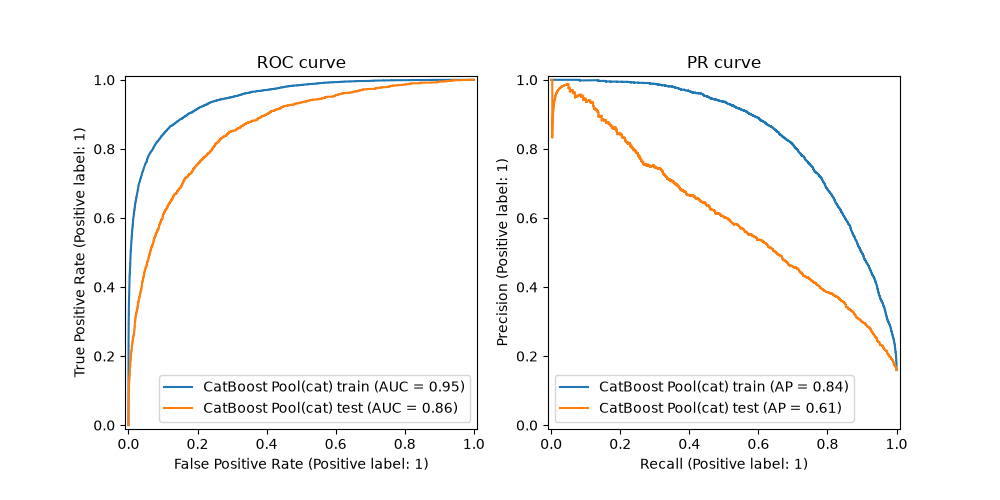

In [99]:
fig, ax = roc_pr_curve_plot_from_predictions(cb_model, train_data_cat_te, test_data_cat_te, "CatBoost Pool(cat)")

Визуализируем все эксперименты (`subdirs=True`):

In [100]:
train_name = 'all_exps'
w = cb.MetricVisualizer('data/catboost_metadata', subdirs=True)
w.start()
if compute_and_dump_data:
    embed_minimal_html(f'data/widgets/catboost_widget_{train_name}_export.html', views=w, title=f'CatBoost MetricVisualizer widget \"{train_name}\" export')
render_widget_export_link(train_name)

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

<div style='font-size: 13pt;'><br>

> HTML-экспорт виджета: [catboost_widget_all_exps_export.html](data/widgets/catboost_widget_all_exps_export.html).

</div>

## 9.9 Важность признаков. Библиотека SHAP

На примере полученной с использованием $CatBoost$ модели рассмотрим важность признаков. Также воспользуемся библиотекой [`shap`](https://pypi.org/project/shap/), чтобы визуализировать наши признаки.

```bash
uv pip install -U shap
```

Значения Шепли применяются в экономике, а точнее &ndash; в теории кооперативных игр. Такие значения назначаются игрокам сообразно их вкладу в игру. В сфере машинного обучения идея использования значений Шепли нашла отражение во фреймворке $SHAP$ ($\textit{SHapley Additive exPlanations}$). Он представляет собой эффективный инструмент для интерпретации механизмов функционирования моделей.

$SHAP$-значение признака позволяет измерить вклад признака в то, насколько предсказание модели отклоняется от ожидаемого прогнозируемого значения или приближается к нему.

Подробнее в [Что внутри черного ящика: понимаем работу ML-модели с помощью SHAP @ Хабр](https://habr.com/ru/companies/wunderfund/articles/739744/).

Предсказание модели:

$$
f(x) = \phi_0 + \sum_{i = 0}^M \phi_i,
$$
где:
- $f(x)$ &ndash; итоговое предсказание модели для конкретного объекта (*predicted value*)
- $\phi_0$ &ndash; среднее предсказание модели на всем обучающем наборе данных (точка отсчета, *base value* или *expected value*)
- $\phi_i$ &ndash; вклад каждого признака $i$ (*SHAP value*), который может быть положительным (увеличивает предсказание) или отрицательным (уменьшает его)

In [101]:
import shap
shap.__version__

'0.54.1'

In [102]:
importances = cb_model.get_feature_importance(prettified=True)
importances

,Feature Id,Importances
0,Humidity3pm,17.090715
1,Location,10.906678
2,Pressure3pm,8.881001
3,WindGustSpeed,5.983783
4,Pressure9am,5.012748
5,MinTemp,4.478899
6,WindDir3pm,4.307038
7,Month,4.238345
8,Temp3pm,4.225923
9,Humidity9am,4.150327


Иногда хочется посмотреть важность фичей не по всей выборке, а по конкретному объекту, для этого необходимо воспользоваться `shap_values`, в этом случае мы получим матрицу, где число строк будет такое же как число объектов, а число столбцов будет равно «число фичей + 1»:

In [103]:
shap_values = cb_model.get_feature_importance(train_data_cat, fstr_type='ShapValues')
print(shap_values.shape)

(39896, 25)


Теперь воспользуемся библиотекой [`shap`](https://pypi.org/project/shap/), чтобы визуализировать наши фичи.

#### Force plot

API Reference: [shap.plots.force](https://shap.readthedocs.io/en/latest/generated/shap.plots.force.html).

Инициализируем объект `tree_explainer` класса `shap.TreeExplainer`, передадим в конструктор обученную модель. Из `tree_explainer` получим $SHAP$-значения `te_shap_values`. Построим график для $3$-го объекта из обучающей выборки.

In [104]:
tree_explainer = shap.TreeExplainer(cb_model)
te_shap_values = tree_explainer.shap_values(train_data_cat)

shap.initjs()
shap_fp = shap.plots.force(tree_explainer.expected_value, te_shap_values[3,:], X_cat_train.iloc[3,:])

# Принудительно меняем цвет фона, например, для темных тем
# https://stackoverflow.com/a/76297464
HTML(f"<div style='background-color: Lavender;'>{shap.getjs() + shap_fp.html()}</div>")

> Вставка кода с подменой фона нужна для темных тем, ибо порождаемый JS-либой график имеет прозрачный фон.

На данном графике признаки, выделенные красным цветом, двигают наше предсказание в положительную сторону, они увеличивают вероятность того, что завтра будет дождь, а выделенные синим цветом &ndash; наоборот, уменьшают данную вероятность.

Сделаем то же самое не для одного объекта, как это было выше, а сразу, допустим, для двухсот объектов из нашей выборки:

In [105]:
X_cat_train_sub = X_cat_train.iloc[0:200]
te_shap_values_sub = te_shap_values[:200]
shap_fp = shap.plots.force(tree_explainer.expected_value, te_shap_values_sub, X_cat_train_sub)

HTML(f"<div style='background-color: Lavender;'>{shap.getjs() + shap_fp.html()}</div>")

По оси $Y$ у нас расположена шкала вклада значения фичи, по оси $X$ &ndash; количество объектов.

#### Bar plot

API Reference: [shap.plots.bar](https://shap.readthedocs.io/en/latest/generated/shap.plots.bar.html).

API Example: [shap.plots.bar](https://shap.readthedocs.io/en/latest/example_notebooks/api_examples/plots/bar.html)

##### Глобальный bar plot для всех признаков

Для того чтобы определить то, какие признаки, в целом, являются наиболее важными для прогнозов, выдаваемых моделью, можно использовать столбчатую диаграмму `shap.plots.bar`, отражающую результаты усреднения $SHAP$‑значений по всем наблюдениям. Расчёт среднего на основании абсолютных значений показателей позволяет добиться того, чтобы положительные и отрицательные значения не уничтожали бы друг друга.

> *Пришлось все вызовы построения графиков, в которых под капотом используется `matplotlib`, обернуть в `fig, ax = plt.subplots()` и `fig.tight_layout()`, иначе вывод осуществлялся в предыдущую фигуру.*

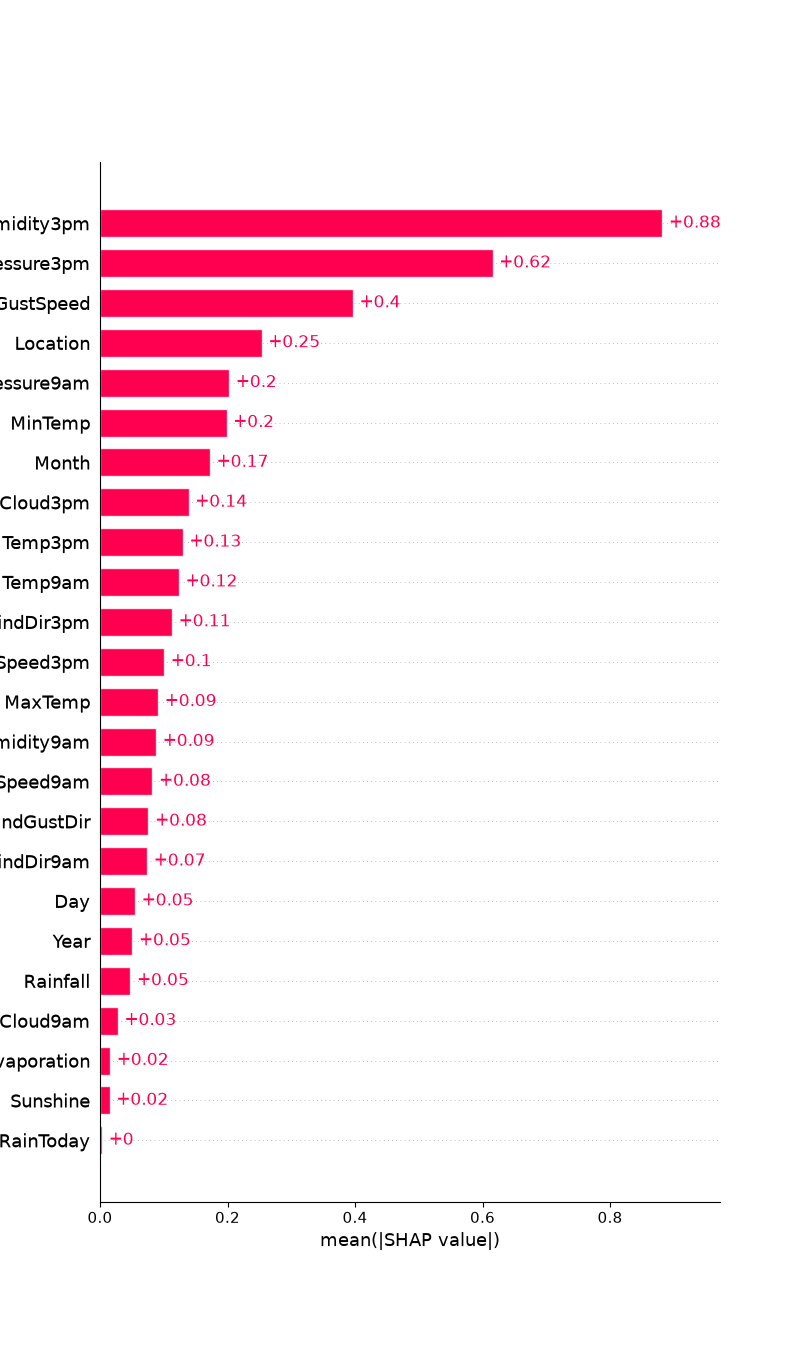

In [106]:
te_df_shap_values = tree_explainer(X_cat_train)
fig, ax = plt.subplots()
shap_bp = shap.plots.bar(te_df_shap_values, max_display=X_cat_train.shape[1])
fig.tight_layout()

Каждому признаку соответствует свой элемент диаграммы, размер которого отражает среднее $SHAP$‑значение. Например, у нас получилось, что самое большое среднее $SHAP$‑значение имеет признак `Humidity3pm`. Это указывает на то, что данный признак оказывает наиболее сильное воздействие на прогнозы модели. Эта информация поможет нам понять то, какие признаки являются наиболее важными в процессе принятия решений, реализуемом моделью.

##### Локальный bar plot для одного объекта

Эта диаграмма позволит нам визуализировать индивидуальные $SHAP$-значения каждого образца в наборе данных. Построим диаграмму для $3$ образца.

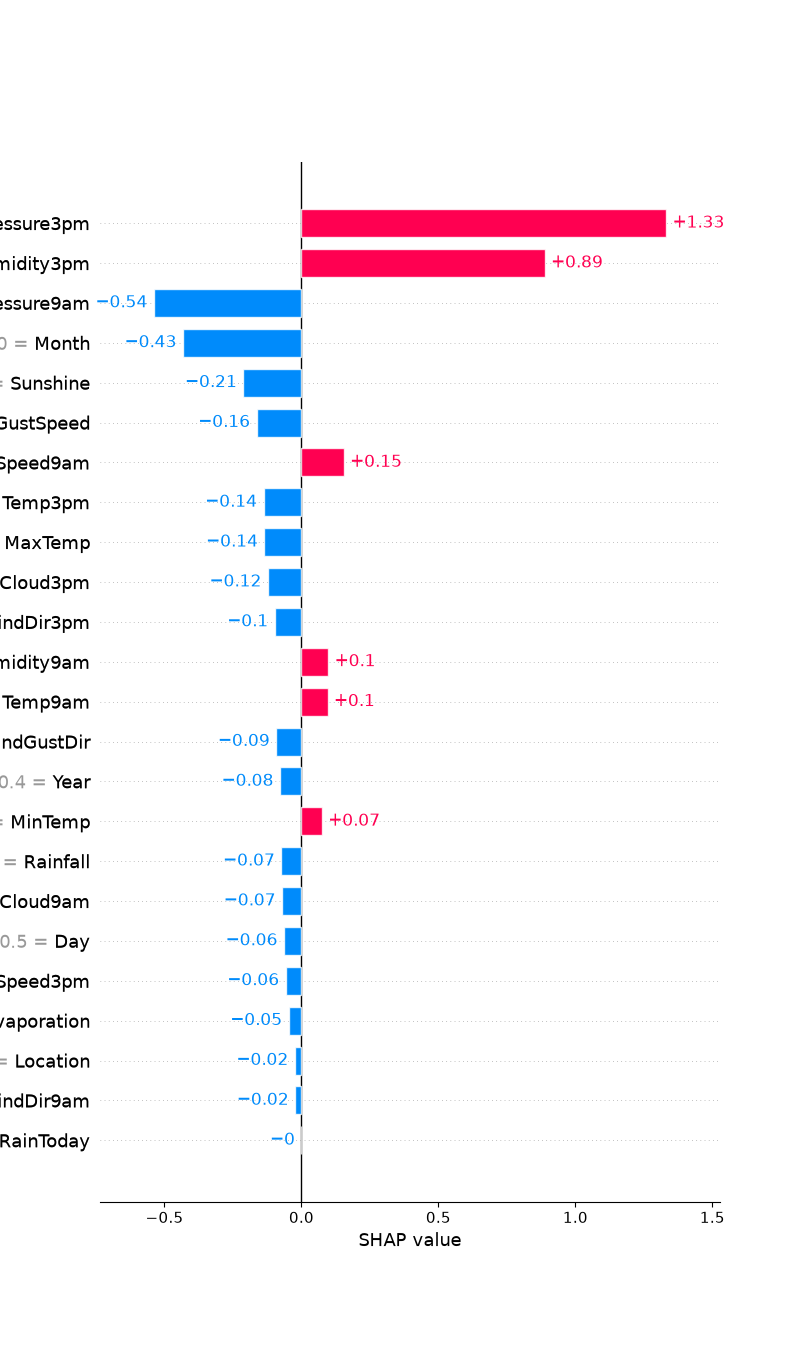

In [107]:
fig, ax = plt.subplots()
shap_bp = shap.plots.bar(te_df_shap_values[3], max_display=X_cat_train.shape[1])
fig.tight_layout()

#### Cohort bar plot

API Exaples: [cohort bar plot](https://shap.readthedocs.io/en/latest/example_notebooks/api_examples/plots/bar.html#Cohort-bar-plot).

Данный график отображает важность признаков в разрезе классов друго признака.

In [108]:
X_cat_train[cat_cols].nunique()

Location       49
WindGustDir    16
WindDir9am     16
WindDir3pm     16
RainToday       2
dtype: int64

Выберем `RainToday` для наглядности (всего 2 уникальных значения).

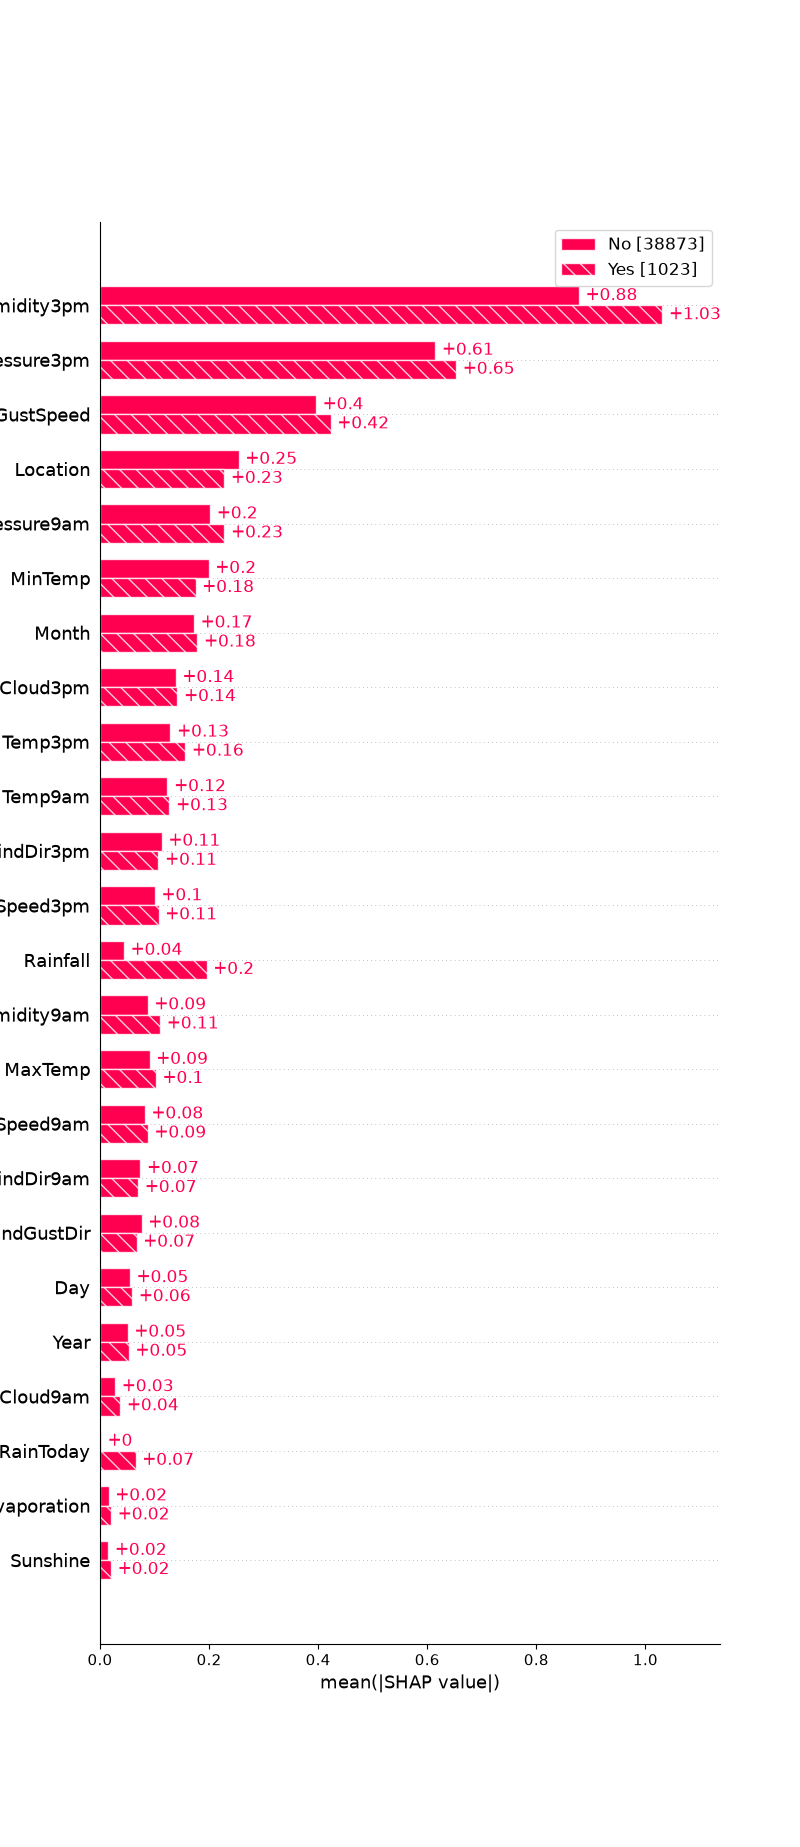

In [109]:
cohort_col_values = X_cat_train_cb['RainToday'].to_numpy()
fig, ax = plt.subplots()
shap.plots.bar(te_df_shap_values.cohorts(cohort_col_values).abs.mean(0), max_display=X_cat_train_cb.shape[1])
fig.tight_layout()

#### Waterfall plot

API Reference: [shap.plots.waterfall](https://shap.readthedocs.io/en/latest/generated/shap.plots.waterfall.html).

API Examples: [waterfall plot](https://shap.readthedocs.io/en/latest/example_notebooks/api_examples/plots/waterfall.html).

Эта диаграмма позволяет нам визуализировать индивидуальные $SHAP$-значения каждого образца в наборе данных. Построим диаграмму для $3$ образца.

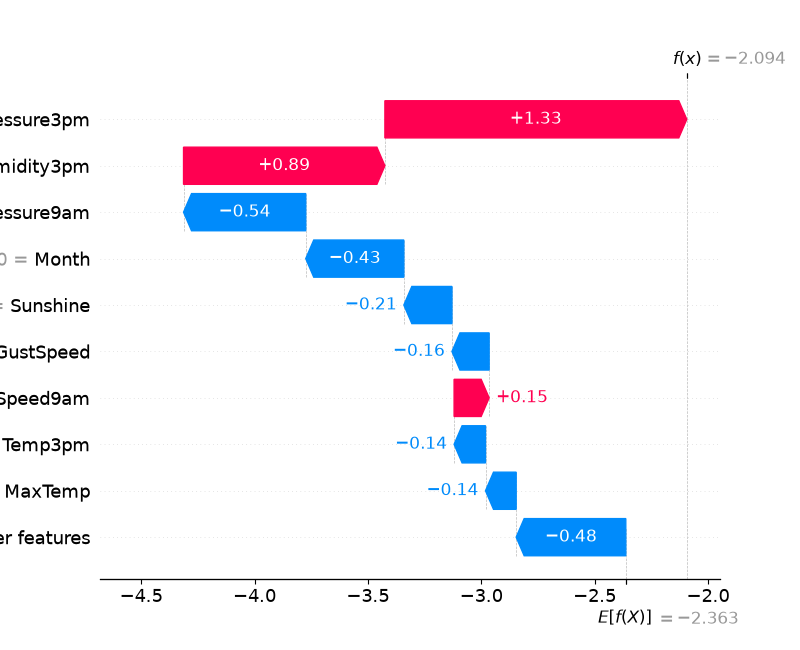

In [110]:
te_df_shap_values_expln = te_df_shap_values[3]
fig, ax = plt.subplots()
shap.plots.waterfall(te_df_shap_values_expln)
fig.tight_layout()

In [111]:
text_md = f"Если сложить все эти значения, положительные и отрицательные, с ${te_df_shap_values_expln.base_values:.3f}$, то получится спрогнозированное значение ${te_df_shap_values_expln.base_values + np.sum(te_df_shap_values_expln.values):.3f}$. Наибольшее влияние на прогноз оказывает признак `Pressure3pm`."
render_styled_markdown(text_md)

<div style='font-size: 13pt;'><br>

>Если сложить все эти значения, положительные и отрицательные, с $-2.363$, то получится спрогнозированное значение $-2.094$. Наибольшее влияние на прогноз оказывает признак `Pressure3pm`.

</div>

#### Scatter plot

API Reference: [shap.plots.scatter](https://shap.readthedocs.io/en/latest/generated/shap.plots.scatter.html).

API Examples: [shap.plots.scatter](https://shap.readthedocs.io/en/latest/example_notebooks/api_examples/plots/scatter.html).

Для того чтобы лучше понять взаимоотношения между отдельными значениями признаков и их $SHAP$‑значениями, можно создать диаграмму зависимости `shap.plots.scatter`. Это диаграмма, которая раскрывает взаимоотношения между $SHAP$‑значениями и значениями признаков для отдельных признаков. Ось $X$ это значение признака, ось $Y$ &ndash; его $SHAP$-значение.

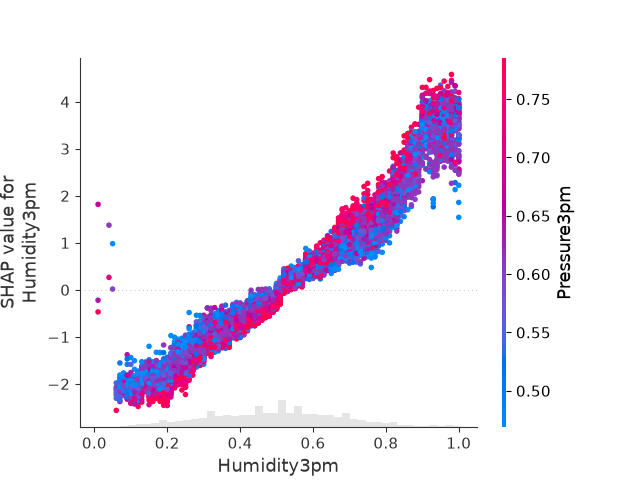

In [112]:
fig, ax = plt.subplots()
shap.plots.scatter(te_df_shap_values[:, "Humidity3pm"], color=te_df_shap_values[:, "Pressure3pm"], ax=ax)
fig.tight_layout()

На графике можно увидеть корреляцию между `Humidity3pm` и `Pressure3pm`.

Также можно проанализировать признак относительно себя самого.

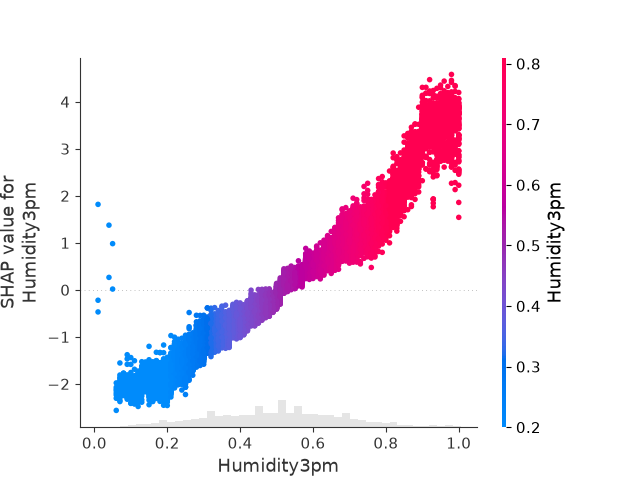

In [113]:
fig, ax = plt.subplots()
shap.plots.scatter(te_df_shap_values[:, "Humidity3pm"], color=te_df_shap_values[:, "Humidity3pm"], ax=ax)
fig.tight_layout()

> Чем больше значение признака (влажность), тем сильнее он двигает результат предсказания в положительную сторону.

#### Beeswarm plot

API Reference: [shap.plots.beeswarm](https://shap.readthedocs.io/en/latest/generated/shap.plots.beeswarm.html).

API Examples: [shap.plots.beeswarm](https://shap.readthedocs.io/en/latest/example_notebooks/api_examples/plots/beeswarm.html).

Диаграмма `shap.plots.beeswarm` &ndash; это полезный инструмент, позволяющий визуализировать все $SHAP$‑значения для каждого признака. По оси $X$ этой диаграммы $SHAP$‑значения сгруппированы по признакам. А цвет точек указывает на соответствующее значение признака. Обычно точки, цвет которых ближе к красному, указывают на более высокие значения признаков.

Диаграмма `shap.plots.beeswarm` может помочь в выявлении важных взаимоотношений между признаками и прогнозами модели. На нашей диаграмме признаки упорядочены по их средним $SHAP$‑значениям.

C:\Users\UD\AppData\Local\Temp\ipykernel_244792\937896627.py:1: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots()


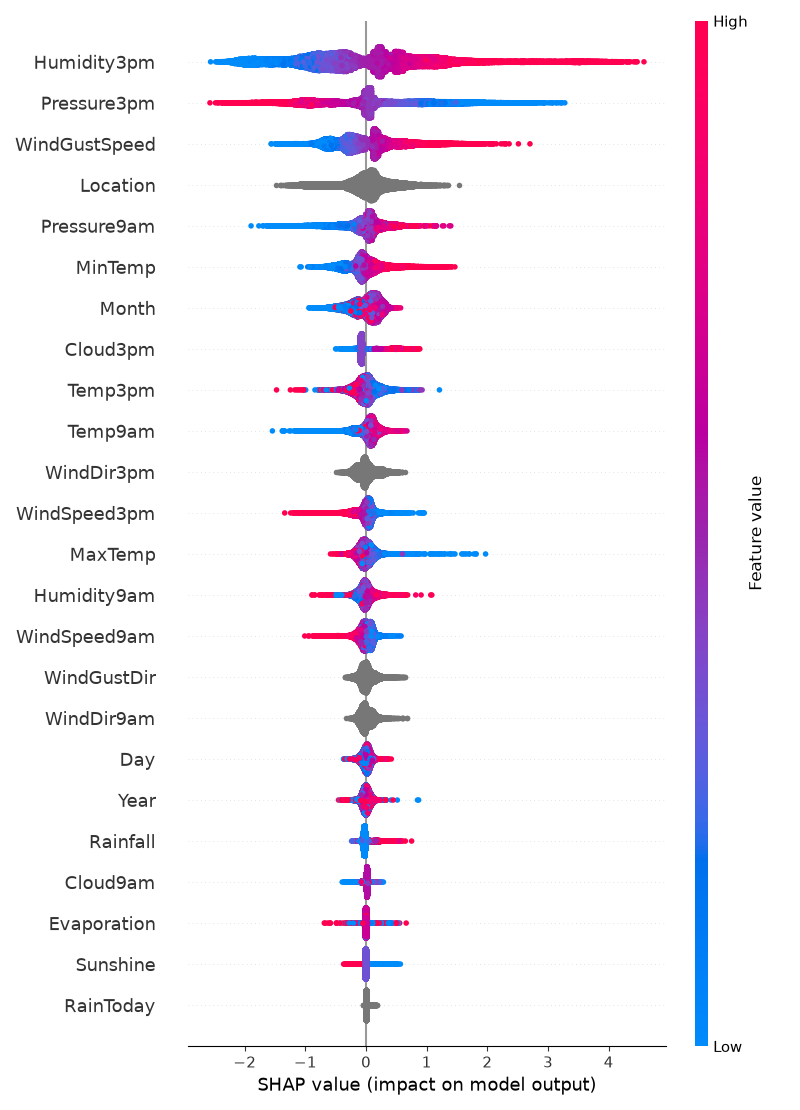

In [114]:
fig, ax = plt.subplots()
shap.plots.beeswarm(te_df_shap_values, max_display=X_cat_train_cb.shape[1], show=False)
fig.tight_layout()

Исследуя $SHAP$‑значения на этой диаграмме, мы можем начать понимать природу взаимоотношений между признаками и спрогнозированной вероятностью дождя завтра. Например, в случае с признаком `Humidity3pm`, видно, что $SHAP$‑значения растут по мере роста значения признака. Это указывает на то, что более высокие значения `Humidity3pm` соответствуют более высокой спрогнозированной вероятностью дождя завтра.

Видна тут и обратная ситуация, связанная с признаками `Pressure3pm` и `MaxTemp`, например. Здесь чем больше значения признаков, тем меньше $SHAP$‑значения. Это наблюдение указывает на то, что более высокие значения `Pressure3pm` и `MaxTemp` связаны с более низкими спрогнозированными вероятностями дождя завтра.

Серым цветом раскрашены категориальные признаки, которые не могут быть соотнесены к численному критерию «меньше-больше».

С $SHAP$ можно визуализировать даже вклад отдельных пикселей в изображении для получения прогноза модели: [Tutorial: Explainable Machine Learning with Python and SHAP](https://mlconference.ai/blog/tutorial-explainable-machine-learning-with-python-and-shap/).